In [1]:
import os
import json
import random
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pickle
import pandas as pd
import torch
import torch.nn.functional as F
import re


import contextlib
import hashlib
import inspect
import platform
import sys


In [2]:
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'  
torch.cuda.empty_cache()

In [3]:
from modules import (
    get_data_from_trajectory_id,
    Step_1,
    Step_2,
    CombinedHamiltonianLayer,
    SimpleStackedHamiltonianNetwork,
    ReverseStep2,
    ReverseStep1,
    ReverseCombinedHamiltonianLayer,
    InverseStackedHamiltonianNetwork,
    prediction_loss,
    prediction_loss_euclidean,
    load_checkpoint,
    count_parameters,
    hsic_loss_statistics_only,

    )

In [4]:
from modules import (    
    time_inference_gpu,
    test_model_all_observations_all_trajectories,
    plot_summary_statistics,
    time_inference_gpu_single_trajectory,
    test_model_varying_observation_single_trajectory,
    plot_varying_observation_results,
    test_model_variance_with_varying_observed_points,
    plot_variance_results,
    test_model_in_single_trajectory,
    visualize_epoch_metrics,
    compute_jacobian_functional,
    compute_symplectic_product,
    test_canonical_transformation_on_trajectory,
    attach_traj_id,
    infer_dt,
    local_lyapunov_times,
    summarize_task,
    row_to_latex,
    run_constancy_experiment_1d,
    )

In [5]:
save_dir_path = "./save_directory_noisy_full_pred_low_samples_pendulum_4" 


In [6]:
with open("all_dataframes_low_samples_pendulum.pkl", "rb") as f:
    loaded_dfs_low_samples_pendulum = pickle.load(f)

# Access them like before:
train_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_df_low_samples_pendulum']
val_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['val_df_low_samples_pendulum']
test_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['test_df_low_samples_pendulum']

train_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_id_df_low_samples_pendulum']
val_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['val_id_df_low_samples_pendulum']
test_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['test_id_df_low_samples_pendulum']

with open("df_high_energy_low_samples_pendulum.pkl", "rb") as f:
    df_high_energy_low_samples_pendulum = pickle.load(f)

val_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_df_high_energy_low_samples_pendulum']
val_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_id_df_high_energy_low_samples_pendulum']

test_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_df_high_energy_low_samples_pendulum']
test_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_id_df_high_energy_low_samples_pendulum']

with open("all_dataframes_low_samples_multiple_periods_pendulum.pkl", "rb") as f:
    df_low_samples_multiple_periods_pendulum = pickle.load(f)

test_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['data_df_low_samples_multiple_periods_pendulum']
test_id_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['id_df_low_samples_multiple_periods_pendulum']



In [9]:
import numpy as np, pandas as pd
SIGMA2_OLD = 0.1
COORDS = ['x', 'u']

per_traj = []
for tid in train_id_df_low_samples_pendulum['trajectory_id'].astype(int):
    sub = get_data_from_trajectory_id(train_id_df_low_samples_pendulum,
                                      train_df_low_samples_pendulum, [tid])
    if sub is not None and len(sub) > 1:
        per_traj.append(sub[COORDS].var(ddof=0))
within = pd.concat(per_traj, axis=1).T.mean()
pooled = train_df_low_samples_pendulum[COORDS].var(ddof=0)

print("=== Task 2 (ideal pendulum) ===")
for c in COORDS:
    print(f"  {c}: within_var={within[c]:.4e}  pooled_var={pooled[c]:.4e}  "
          f"SNR_within@0.1={within[c]/SIGMA2_OLD:6.2f}  SNR_pooled@0.1={pooled[c]/SIGMA2_OLD:6.2f}")
print("\nPaste this line into the HH notebook:")
print("  ('Task2', {" + ", ".join(f"'{c}': {within[c]:.6e}" for c in COORDS) + "}),")

=== Task 2 (ideal pendulum) ===
  x: within_var=6.6910e-01  pooled_var=6.7111e-01  SNR_within@0.1=  6.69  SNR_pooled@0.1=  6.71
  u: within_var=1.7024e+00  pooled_var=1.7082e+00  SNR_within@0.1= 17.02  SNR_pooled@0.1= 17.08

Paste this line into the HH notebook:
  ('Task2', {'x': 6.691010e-01, 'u': 1.702431e+00}),


In [7]:


DATA_DF   = train_df_low_samples_pendulum
ID_DF     = train_id_df_low_samples_pendulum
TASK_NAME = "T1 (mass--spring)"
Q_COLS    = ["x"];  P_COLS = ["u"]
N_MIN     = 5;      R_MIN  = 7
SEED      = 0;      

# ----- prepare -----
df = attach_traj_id(DATA_DF, ID_DF)
dt = infer_dt(df)
print(f"[data] {TASK_NAME}: {len(df)} samples, "
      f"{df['traj_id'].nunique()} trajectories, dt={dt:.4g}")

# ----- estimate (seed printed in the [setup] block) -----
tau_L, details = local_lyapunov_times(
    df, dt=dt,
    min_neighbors=N_MIN,          # REQUIRED
    min_region_points=R_MIN,      # REQUIRED
    q_cols=Q_COLS, p_cols=P_COLS, t_col="t",
    traj_col="traj_id",
    w=None,                 # self-defined if None
    K_max=None,             # self-defined if None
    n_eps=8, eps_lo_pct=1.0, eps_hi_pct=20.0,
    lpower=1.0, epower=1.0,
    fwhm_frac_max=0.25,
    zero_tol_factor=2.0,
    min_valid_eps=5,
    curve_len_factor=4,
    rng=0, 
    return_details=True,
    verbose=True)

# ----- summarize into the standardized record -----
rec = summarize_task(TASK_NAME, df, tau_L, details, n_min=N_MIN, r_min=R_MIN)

# ----- report: the table row and the final T_max -----
print(f"\n[seed] rng={SEED}")
print(f"[T_record] {rec['T_record']:.3f}   [T_max] {rec['T_max']:.3f}")
if not np.isclose(rec['T_max'], rec['T_record']):
    print("[note] estimator SHORTENED the segment: T_max < T_record "
          "(the min actually bit — verify this row deliberately).")
print("\nLaTeX row:")
print(row_to_latex(rec))



[data] T1 (mass--spring): 750 samples, 25 trajectories, dt=0.14
[setup] N=750 samples, 25 trajectories, dim(q,p)=2
[setup] Theiler w=14 steps, K_max=29 steps
[setup] eps-subsample seed (rng)=0
[setup] eps grid: [0.1284 0.1702 0.2255 0.2989 0.3962 0.5251 0.6959 0.9223]
[done] finite tau_L: 10, inf (regular): 515, NaN: 225

[seed] rng=0
[T_record] 4.060   [T_max] 4.060

LaTeX row:
T1 (mass--spring) & 5 & 7 & 750 & 515 & 10 & 225 & $19.15$ & $30.45$ & $13.46$ & $4.060$ & $4.060$ \\


In [8]:
Tmax = np.float32(rec["T_max"])
Tmax

np.float32(4.06)

In [7]:
Tmax = 4.06


📊 Metric summaries:
  Lowest loss of metric 'val_prediction_loss_' recorded in epoch 1157 with the value: 0.1069, the losses of the last 5 epochs are: ['0.1077', '0.1100', '0.1083', '0.1084', '0.1069']
  Lowest loss of metric 'val_prediction_loss_training_set' recorded in epoch 1134 with the value: 0.0948, the losses of the last 5 epochs are: ['0.0957', '0.0970', '0.0983', '0.1003', '0.0968']
  Lowest loss of metric 'train_total_loss_' recorded in epoch 1139 with the value: 0.4094, the losses of the last 5 epochs are: ['0.4376', '0.4437', '0.4547', '0.4308', '0.4332']
  Lowest loss of metric 'train_hsic_loss_' recorded in epoch 254 with the value: 0.0000, the losses of the last 5 epochs are: ['0.0002', '0.0001', '0.0001', '0.0000', '0.0001']
  Lowest loss of metric 'validation_criterio' recorded in epoch 1157 with the value: 0.0883, the losses of the last 5 epochs are: ['0.0890', '0.0908', '0.0894', '0.0895', '0.0883']
  Lowest loss of metric 'mean_grad_norm_' recorded in epoch 0 with

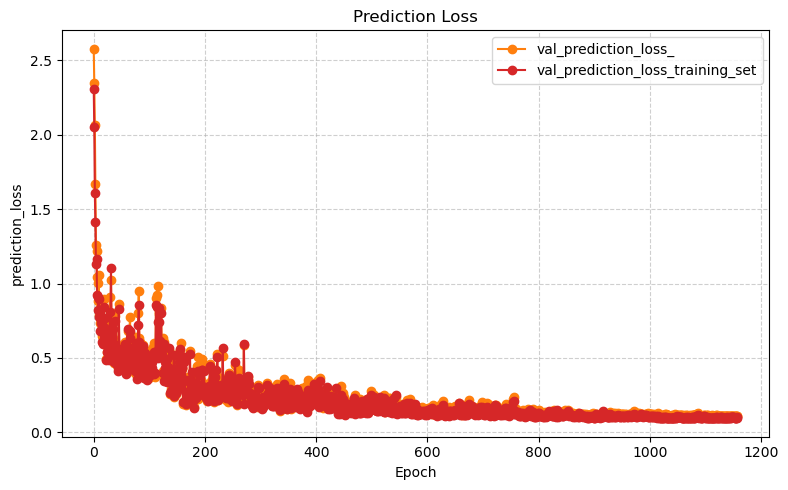

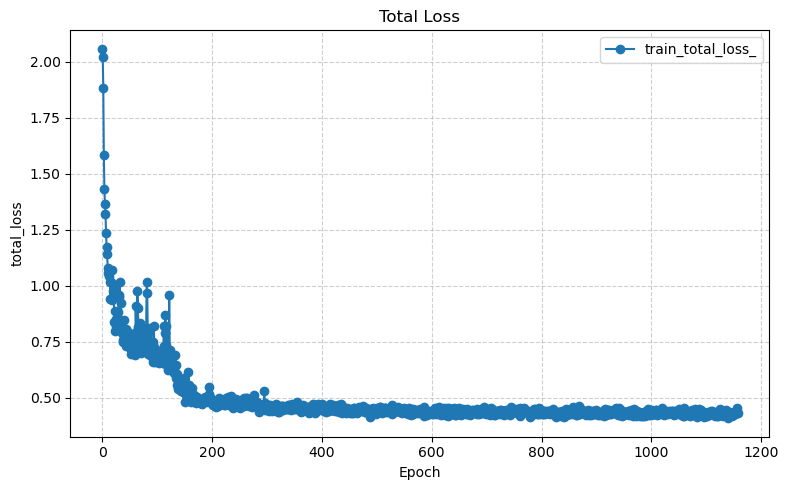

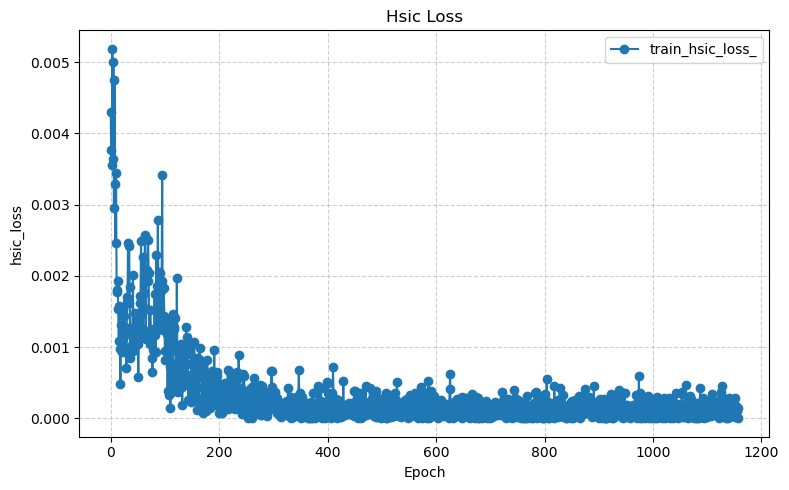

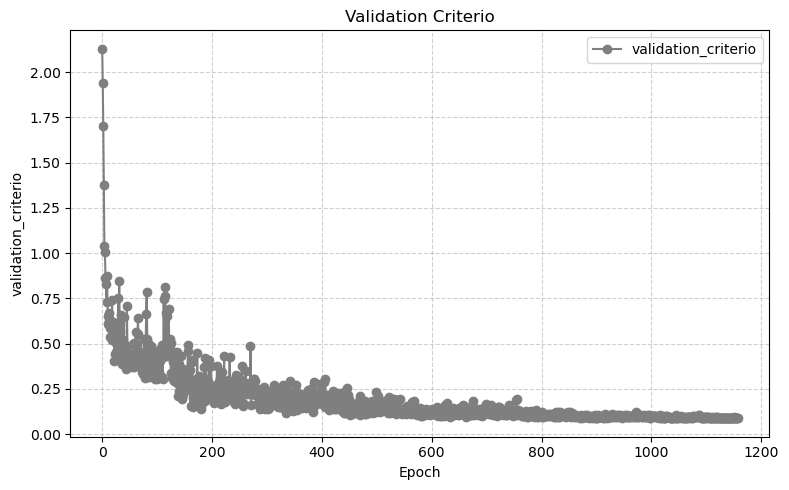

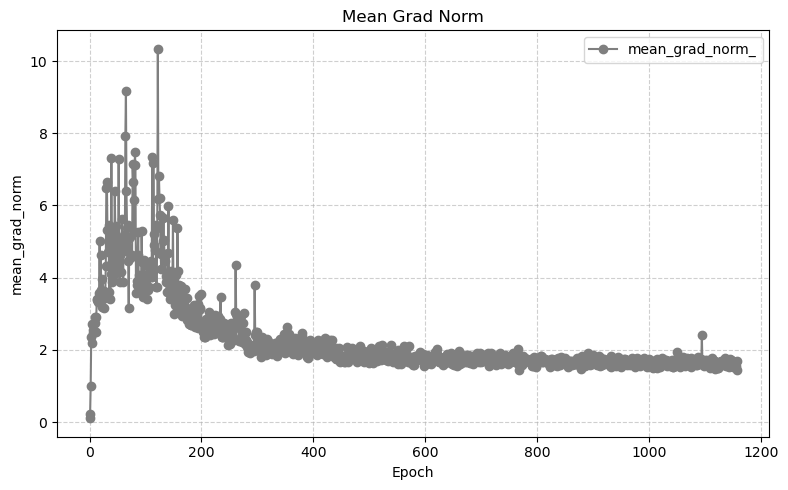

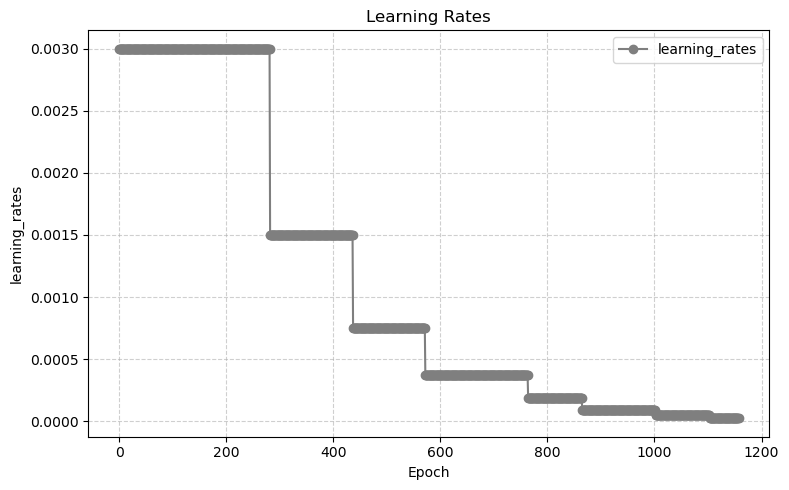

In [6]:
visualize_epoch_metrics(
 save_dir_path,
["val_prediction_loss_", "val_prediction_loss_training_set", "train_total_loss_", "train_hsic_loss_" , "validation_criterio", "mean_grad_norm_", "learning_rates"],
plot_on_same_graph=True,
verbose=True,
specific_epochs=None
)


In [8]:
device = "cuda"
mapping_net = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)

In [9]:


checkpoint_path = os.path.join(save_dir_path, "best_model.pt")

load_checkpoint(path=checkpoint_path, mapping_net=mapping_net, device=device, optimizer=None, scheduler=None)

inverse_net = InverseStackedHamiltonianNetwork(forward_network=mapping_net)


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [10]:
canonicity_results = test_canonical_transformation_on_trajectory(get_data_from_trajectory_id,
    compute_jacobian_functional,
    compute_symplectic_product,                                            
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    5,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    tolerance=1e-5,
    verbose=True,)

=== Canonical Transformation Test — Trajectory 5 ===
(5 segment(s), 144 total points, tolerance=1.0e-05)

MappingNet: d(Q,P)/d(q,p)
  ✓ All 144 points pass (max residual: 5.96e-07)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   1.54e-07 (std=1.21e-07)
    Median: 1.19e-07 [IQR: 5.96e-08, 2.38e-07]
    Min:    0.00e+00
    Max:    5.96e-07

InverseNet: d(q,p)/d(Q,P)
  ✓ All 144 points pass (max residual: 4.77e-07)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   1.49e-07 (std=1.24e-07)
    Median: 1.19e-07 [IQR: 5.96e-08, 2.38e-07]
    Min:    0.00e+00
    Max:    4.77e-07

=== Table row (Task = trajectory 5) ===
  M  max    = 5.96e-07
  M  median = 1.19e-07
  M^-1 max    = 4.77e-07
  M^-1 median = 1.19e-07
  LaTeX: 5.96e-07 & 1.19e-07 & 4.77e-07 & 1.19e-07 \\


In [13]:
print(f"Number of parameters are: {count_parameters(mapping_net)}, with number of training samples: {train_df_low_samples_pendulum.shape[0]}\nThat is a ratio of parameters/samples of: {count_parameters(mapping_net)/train_df_low_samples_pendulum.shape[0]}")

Number of parameters are: 82560, with number of training samples: 750
That is a ratio of parameters/samples of: 110.08


In [13]:

with open("benchmark_outputs/hjn_task2_multiple_periods_final.pkl", "rb") as f:
    time_results_multiple_periods = pickle.load(f)

In [14]:
all_trajectories_results_multiple_periods = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    verbose=True,
)

Observation index 0/143, mean loss across trajectories: 0.309353
Observation index 1/143, mean loss across trajectories: 0.310959
Observation index 2/143, mean loss across trajectories: 0.311933
Observation index 3/143, mean loss across trajectories: 0.308818
Observation index 4/143, mean loss across trajectories: 0.304505
Observation index 5/143, mean loss across trajectories: 0.304474
Observation index 6/143, mean loss across trajectories: 0.306722
Observation index 7/143, mean loss across trajectories: 0.304525
Observation index 8/143, mean loss across trajectories: 0.296039
Observation index 9/143, mean loss across trajectories: 0.288765
Observation index 10/143, mean loss across trajectories: 0.282104
Observation index 11/143, mean loss across trajectories: 0.274509
Observation index 12/143, mean loss across trajectories: 0.270365
Observation index 13/143, mean loss across trajectories: 0.267935
Observation index 14/143, mean loss across trajectories: 0.261849
Observation index 15

In [15]:
#SAVE

with open("./prediction_results_all_trajectories/task_2_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods, f)

In [ ]:
#LOAD
with open("./prediction_results_all_trajectories/task_2_results_multiple_periods.pkl", "rb") as f:
    all_trajectories_results_multiple_periods = pickle.load(f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.213680
Std of medians: 0.095745
Median of medians: 0.209528
IQR of medians: [0.126776, 0.288212]
95% BCa CI for mean of medians (over trajectories): [0.173831, 0.256336]
N_traj=20, N_obs=144

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.162430
Std of medians: 0.074292
Median of medians: 0.157166
IQR of medians: [0.093045, 0.223305]
95% BCa CI for mean of medians (over trajectories): [0.130774, 0.193970]
N_traj=20, N_obs=144


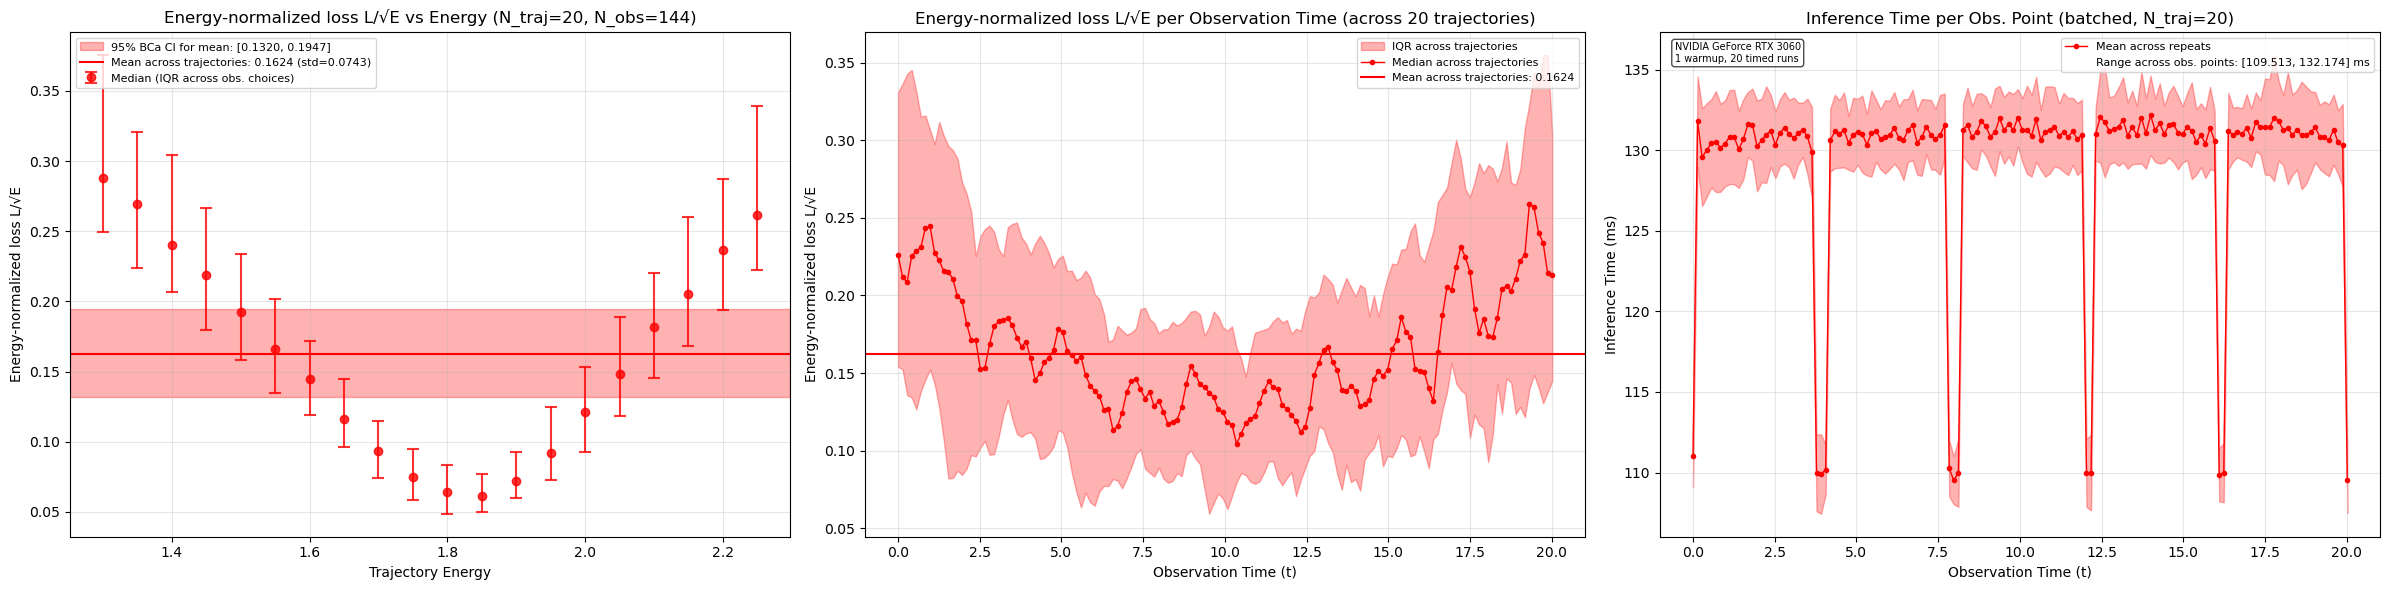

In [16]:
plot_summary_statistics(all_trajectories_results_multiple_periods, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_multiple_periods['timing_stats'], timing_stats_single=None, band_alpha=0.3) 

In [17]:
variance_results_multiple_periods = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.070056
IQR: [0.028931, 0.209960]
95% BCa bootstrap CI for median (over trajectories): [0.030775, 0.158085]
N_traj=20, N_obs=144, N_permutations=20
First valid point count: 3


In [18]:
#SAVE

with open("./variance_results/task_2_variance_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(variance_results_multiple_periods, f)

In [ ]:
#LOAD
with open("./variance_results/task_2_variance_results_multiple_periods.pkl", "rb") as f:
    variance_results_multiple_periods = pickle.load(f)

In [ ]:
plot_variance_results(variance_results_multiple_periods, only_plot_percentage=0.5)

In [19]:
print(all_trajectories_results_multiple_periods['median_representative_id'])

5


In [20]:
single_trajectory_multiple_periods_results = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    all_trajectories_results_multiple_periods['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=True,
)

Observation index 0/143, loss: 0.140633
Observation index 1/143, loss: 0.173262
Observation index 2/143, loss: 0.193163
Observation index 3/143, loss: 0.194681
Observation index 4/143, loss: 0.184197
Observation index 5/143, loss: 0.170068
Observation index 6/143, loss: 0.156817
Observation index 7/143, loss: 0.142744
Observation index 8/143, loss: 0.126336
Observation index 9/143, loss: 0.112910
Observation index 10/143, loss: 0.109963
Observation index 11/143, loss: 0.120104
Observation index 12/143, loss: 0.135668
Observation index 13/143, loss: 0.135799
Observation index 14/143, loss: 0.109434
Observation index 15/143, loss: 0.079127
Observation index 16/143, loss: 0.065191
Observation index 17/143, loss: 0.059569
Observation index 18/143, loss: 0.050038
Observation index 19/143, loss: 0.038636
Observation index 20/143, loss: 0.027491
Observation index 21/143, loss: 0.022551
Observation index 22/143, loss: 0.035804
Observation index 23/143, loss: 0.059146
Observation index 24/143, 

In [21]:
#SAVE

with open("./prediction_results_single_trajectory/task_2_single_traj_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results, f)

In [ ]:
#LOAD
with open("./prediction_results_single_trajectory/task_2_single_traj_results_multiple_periods.pkl", "rb") as f:
    single_trajectory_multiple_periods_results = pickle.load(f)

In [22]:
obs_idx = 0

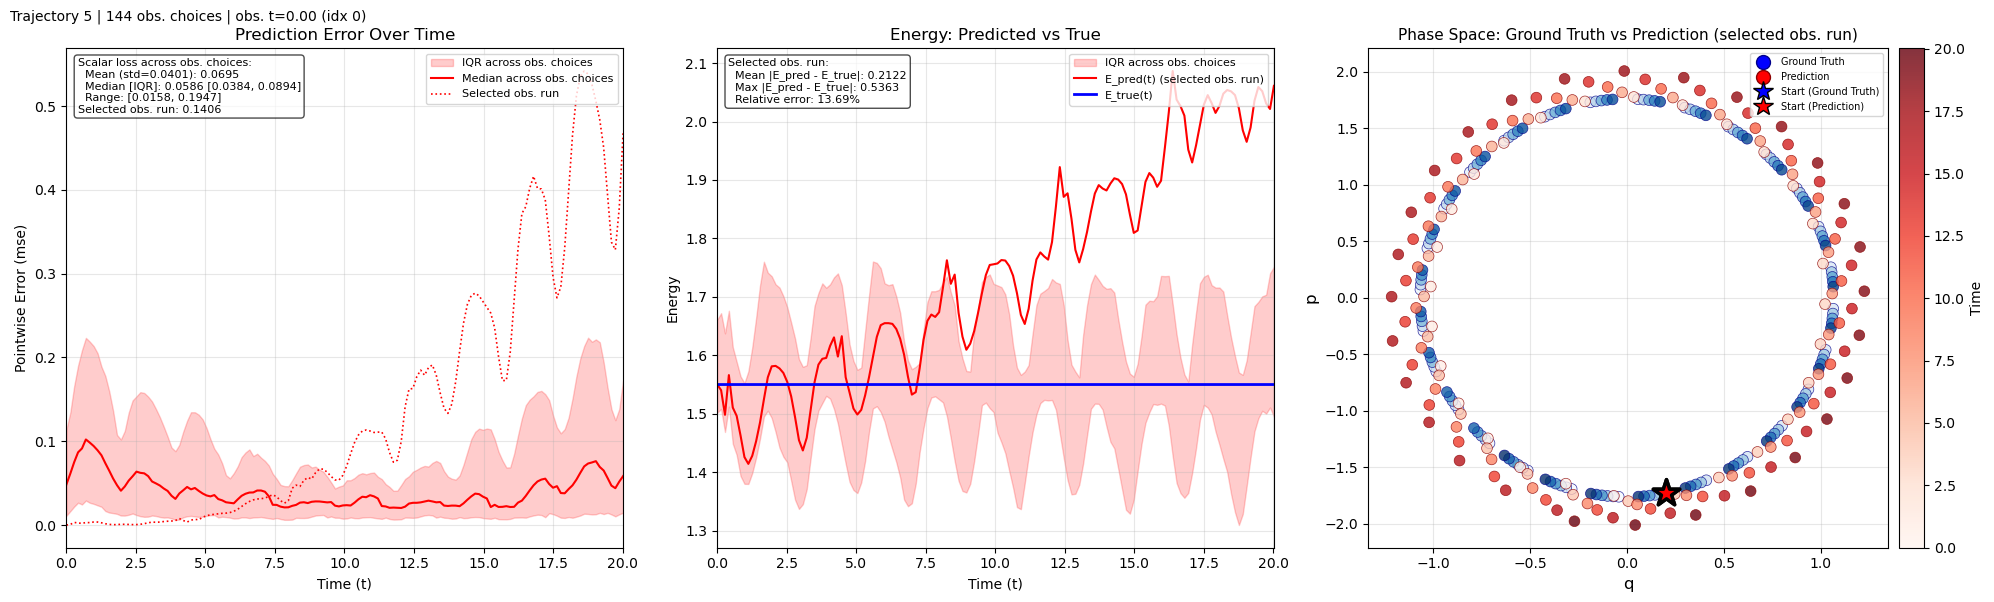

In [23]:
plot_varying_observation_results(single_trajectory_multiple_periods_results, obs_idx=obs_idx, figsize=(20,6), connect_points=False, iqr_alpha = 0.2)

In [24]:
print(f"The max energy of a trajectory in the training set is: {train_id_df_low_samples_pendulum['energy'].max():.3f}\nThe high energy testing set has energies in the range: {test_id_df_high_energy_low_samples_pendulum['energy'].min():.3f}-{test_id_df_high_energy_low_samples_pendulum['energy'].max():.3f}")

The max energy of a trajectory in the training set is: 2.287
The high energy testing set has energies in the range: 2.400-4.431


In [25]:

with open("benchmark_outputs/hjn_task2_high_energy.pkl", "rb") as f:
    time_results_high_energy = pickle.load(f)

In [26]:
all_trajectories_results_high_energy = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    verbose=True,
)

Observation index 0/36, mean loss across trajectories: 0.879507
Observation index 1/36, mean loss across trajectories: 0.838311
Observation index 2/36, mean loss across trajectories: 0.810800
Observation index 3/36, mean loss across trajectories: 0.796225
Observation index 4/36, mean loss across trajectories: 0.758827
Observation index 5/36, mean loss across trajectories: 0.723075
Observation index 6/36, mean loss across trajectories: 0.699390
Observation index 7/36, mean loss across trajectories: 0.671140
Observation index 8/36, mean loss across trajectories: 0.644288
Observation index 9/36, mean loss across trajectories: 0.620956
Observation index 10/36, mean loss across trajectories: 0.600077
Observation index 11/36, mean loss across trajectories: 0.582246
Observation index 12/36, mean loss across trajectories: 0.564462
Observation index 13/36, mean loss across trajectories: 0.542094
Observation index 14/36, mean loss across trajectories: 0.517854
Observation index 15/36, mean loss 

In [27]:
#SAVE

with open("./prediction_results_all_trajectories/task_2_results_high_energy.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_high_energy, f)

In [ ]:
#LOAD
with open("./prediction_results_all_trajectories/task_2_results_high_energy.pkl", "rb") as f:
    all_trajectories_results_high_energy = pickle.load(f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.607911
Std of medians: 0.300170
Median of medians: 0.557088
IQR of medians: [0.355843, 0.876501]
95% BCa CI for mean of medians (over trajectories): [0.459283, 0.773688]
N_traj=13, N_obs=37

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.315705
Std of medians: 0.134146
Median of medians: 0.297776
IQR of medians: [0.208681, 0.437830]
95% BCa CI for mean of medians (over trajectories): [0.245768, 0.386397]
N_traj=13, N_obs=37


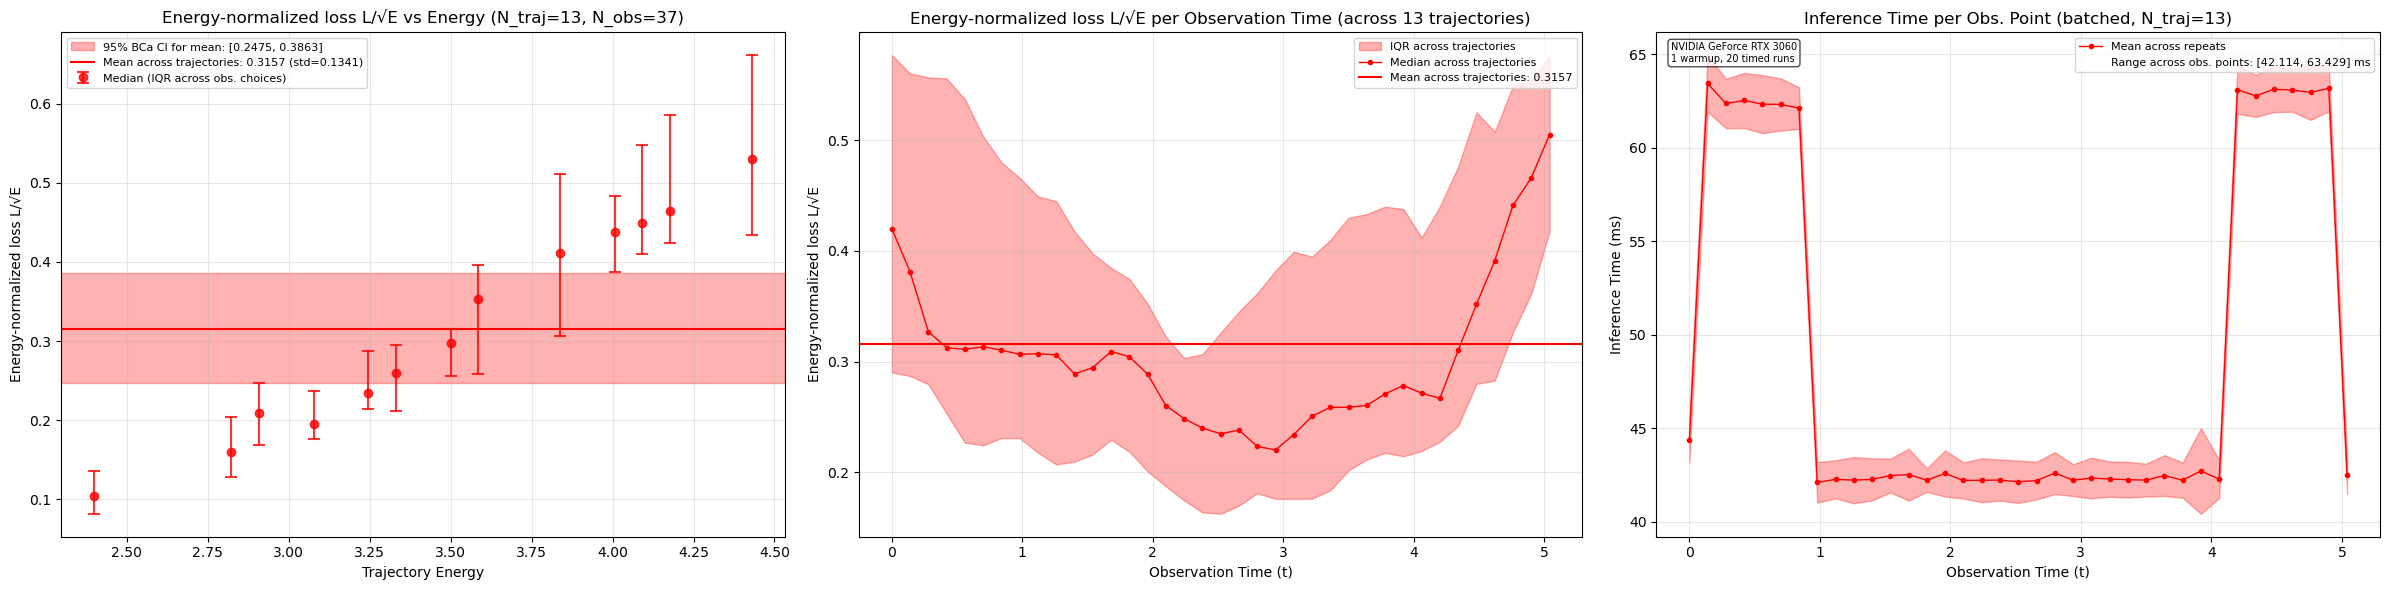

In [28]:
plot_summary_statistics(all_trajectories_results_high_energy, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_high_energy['timing_stats'], timing_stats_single=None, band_alpha=0.3)

In [10]:
variance_results_high_energy = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)


#SAVE

with open("./variance_results/task_2_variance_results_high_energy.pkl", "wb") as f:
    pickle.dump(variance_results_high_energy, f)

Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.214288
IQR: [0.111272, 0.431826]
95% BCa bootstrap CI for median (over trajectories): [0.111272, 0.431826]
N_traj=13, N_obs=37, N_permutations=20
First valid point count: 2


In [ ]:
plot_variance_results(variance_results_high_energy, only_plot_percentage=1.0)

In [10]:


SETS = {"Train": (train_df_low_samples_pendulum, train_id_df_low_samples_pendulum),
"TestA": (test_df_low_samples_multiple_periods_pendulum, test_id_df_low_samples_multiple_periods_pendulum),
"TestB": (test_df_high_energy_low_samples_pendulum, test_id_df_high_energy_low_samples_pendulum)}



res_ip = run_constancy_experiment_1d(
    mapping_net, inverse_net, Tmax=Tmax, sets=SETS, sigma2=0.1,
)


#SAVE

with open("./constancy_results/task_2_constancy_results.pkl", "wb") as f:
    pickle.dump(res_ip, f)







model 53d04f48d6de509f | outputs 1935f1ca6f77eb0e
Train  n_traj=25  n_seg=25  D0 0.0381 [0.0272, 0.0518] | W0max 0.0421 [0.0311, 0.0587] | rms_delta 0.0782 [0.0685, 0.0994] | max_delta 0.136 [0.115, 0.179] | rms_disp 2.21 [1.93, 2.44] | noise ratio 0.175 | D0/Train 1 | floor max 1.77e-06
TestA  n_traj=20  n_seg=100 D0 0.0379 [0.0333, 0.0491] | W0max 0.0523 [0.0384, 0.059] | rms_delta 0.0834 [0.0783, 0.104] | max_delta 0.17 [0.138, 0.191] | rms_disp 2.22 [2.01, 2.49] | noise ratio 0.187 | D0/Train 0.994 | floor max 1.57e-06
TestB  n_traj=13  n_seg=26  D0 0.203 [0.159, 0.323] | W0max 0.249 [0.185, 0.43] | rms_delta 0.672 [0.463, 0.993] | max_delta 1.15 [0.843, 1.93] | rms_disp 3.08 [2.92, 3.24] | noise ratio 1.5 | D0/Train 5.34 | floor max 1.22e-06


In [29]:
print(all_trajectories_results_high_energy['median_representative_id'])

13


In [30]:
single_trajectory_high_energy_results = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    all_trajectories_results_high_energy['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=True,
)

Observation index 0/36, loss: 0.962722
Observation index 1/36, loss: 0.707682
Observation index 2/36, loss: 0.570341
Observation index 3/36, loss: 0.523326
Observation index 4/36, loss: 0.524512
Observation index 5/36, loss: 0.537938
Observation index 6/36, loss: 0.543911
Observation index 7/36, loss: 0.541507
Observation index 8/36, loss: 0.530580
Observation index 9/36, loss: 0.498290
Observation index 10/36, loss: 0.431477
Observation index 11/36, loss: 0.364621
Observation index 12/36, loss: 0.340952
Observation index 13/36, loss: 0.346229
Observation index 14/36, loss: 0.337313
Observation index 15/36, loss: 0.303601
Observation index 16/36, loss: 0.284416
Observation index 17/36, loss: 0.295585
Observation index 18/36, loss: 0.308821
Observation index 19/36, loss: 0.294760
Observation index 20/36, loss: 0.270801
Observation index 21/36, loss: 0.269865
Observation index 22/36, loss: 0.302094
Observation index 23/36, loss: 0.357138
Observation index 24/36, loss: 0.413774
Observatio

In [31]:
#SAVE

with open("./prediction_results_single_trajectory/task_2_single_traj_results_high_energy.pkl", "wb") as f:
    pickle.dump(single_trajectory_high_energy_results, f)

In [ ]:
#LOAD
with open("./prediction_results_single_trajectory/task_2_single_traj_results_high_energy.pkl", "rb") as f:
    single_trajectory_high_energy_results = pickle.load(f)

In [32]:
obs_idx = 0

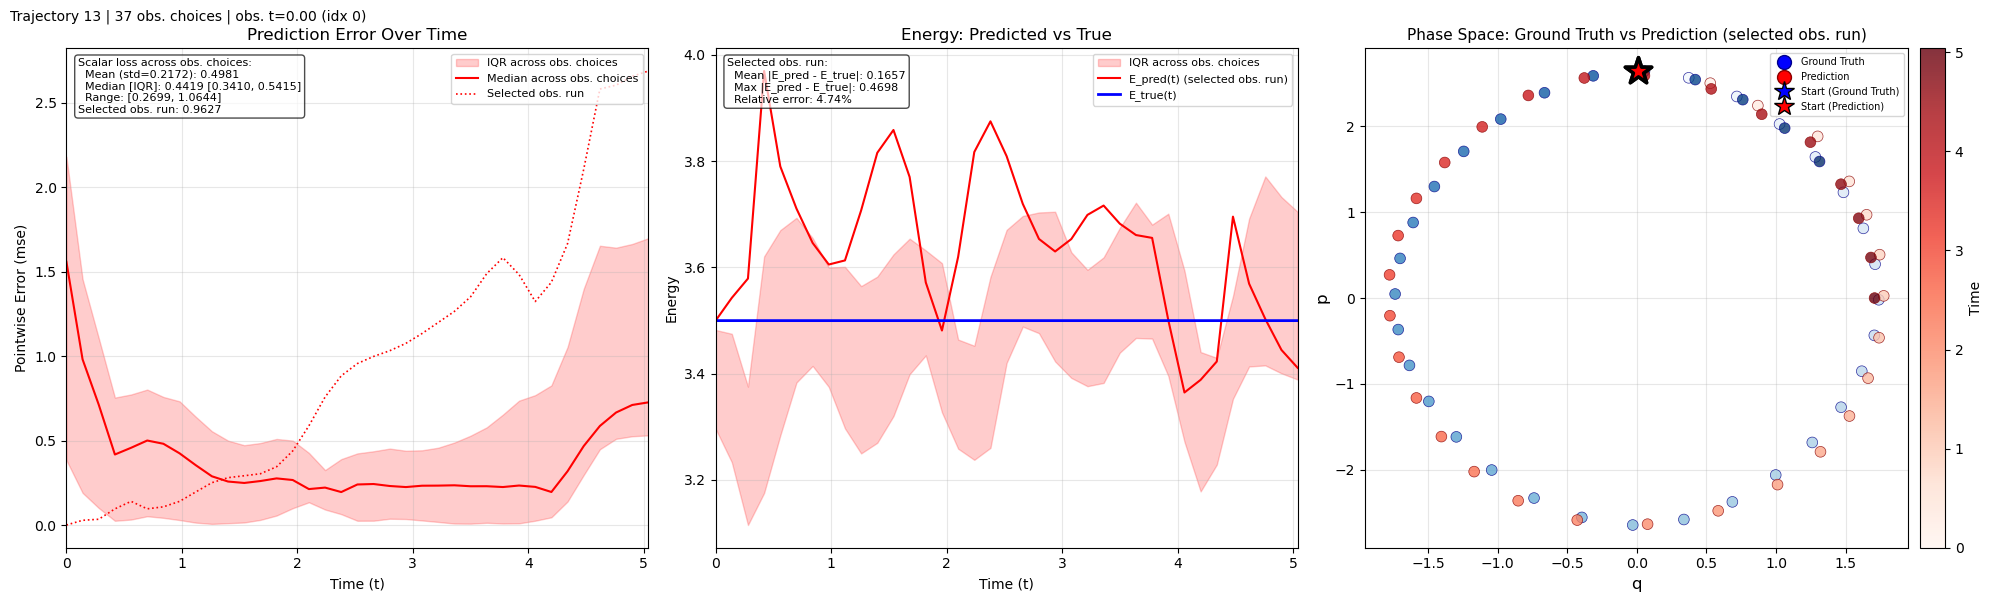

In [34]:
plot_varying_observation_results(single_trajectory_high_energy_results, obs_idx=obs_idx, figsize=(20,6), connect_points=False, iqr_alpha = 0.2)

In [16]:
"""
FULL, SELF-CONTAINED latent <-> physics recovery for HJN -- IDEAL PENDULUM
(oscillatory regime).

    H = 1/2 p^2 + omega0_sq * (1 - cos q),   omega0_sq = g/l = 3,   separatrix E = 6.

This file bundles the feature-agnostic recovery / reporting machinery (the SHO
module's helpers, reproduced verbatim) together with the pendulum-specific physics,
so the ONLY thing you must supply is a trained encoder `mapping_net` and its
`device`.  Run by pasting into a notebook cell, or:  %run -i pendulum_recovery_full.py

PHYSICS CHOICE -- the action-angle theta (not the raw elliptic phase delta).
The SHO's second invariant phi is the polar angle of a circular orbit.  The faithful
pendulum analogue is the ACTION-ANGLE variable theta in [-pi, pi): uniform in time,
2*pi-periodic (so cos/sin/atan2 + unwrap port verbatim) and giving a rectangular
(E, theta) grid.  Its time rate is the anharmonic frequency
    Omega(E) = 2*pi / T(E) = pi * omega0 / (2 K(m)),     m = E / (2 omega0^2),
which DECREASES with energy -- the pendulum slowdown the SHO cannot show.  That
energy-dependent slope in the time-shift test is the physics payoff.  (The raw
elliptic phase delta would instead give a constant slope -omega0 for every state, but
hides the anharmonicity inside K(m) and forces a non-rectangular grid: the weaker
choice here.)  Throughout, res['phi'] HOLDS theta, so every generic reporter that
reads res['phi'] as "the angle" works unchanged.
"""

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import ellipk, ellipj
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

OMEGA0_SQ = 3.0                 # g/l for this task (g=3, l=1)  => omega0 = sqrt(3)
E_SEP     = 2.0 * OMEGA0_SQ     # separatrix energy = 6


# ======================================================================
# Encoder interface  (the one piece that talks to the trained model)
# ======================================================================
def encode_at_reference_time(mapping_net, q, p, device, reference_time=0.0):
    """No torch.no_grad(): the HJL forward uses autograd internally; .detach() outputs."""
    import torch
    q_t = torch.as_tensor(np.asarray(q, np.float32), device=device)
    p_t = torch.as_tensor(np.asarray(p, np.float32), device=device)
    t_t = torch.full_like(q_t, float(reference_time))
    Q, P, _ = mapping_net(q_t, p_t, t_t)
    return Q.detach().cpu().numpy().astype(float), P.detach().cpu().numpy().astype(float)


# ======================================================================
# Generic polynomial read-out machinery  (feature-agnostic; verbatim from SHO module)
# ======================================================================
def _r2(y, yhat):
    y = np.asarray(y, float)
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


def _poly(degree, scale=False):
    """Polynomial least-squares read-out. `scale` standardises inputs; it leaves
    predictions and R^2 unchanged (invertible affine reparam of the features) and only
    changes coefficient values, so it is OFF by default so the fitted model IS the
    equation reported in raw (Q,P) units. Turn ON only if a high-degree solve is
    ill-conditioned; it never affects results."""
    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree, include_bias=True),
              LinearRegression(fit_intercept=False)]
    return make_pipeline(*steps)


def _oof_scalar(feats, y, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, float); pred = np.zeros_like(y)
    for tr, te in kf.split(feats):
        pred[te] = _poly(degree, scale).fit(feats[tr], y[tr]).predict(feats[te])
    return pred




def _oof_phase(feats, phi, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    c, s = np.cos(phi), np.sin(phi); ch, sh = np.zeros_like(c), np.zeros_like(s)
    for tr, te in kf.split(feats):
        m = _poly(degree, scale).fit(feats[tr], np.column_stack([c[tr], s[tr]]))
        o = m.predict(feats[te]); ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)



def angular_error_deg(phi_true, phi_hat):
    d = np.arctan2(np.sin(phi_hat - phi_true), np.cos(phi_hat - phi_true))
    return np.abs(d) * 180.0 / np.pi


def err_stats(abs_err):
    """Descriptive spread (no distributional assumption, no bootstrap)."""
    a = np.asarray(abs_err, float)
    q25, med, q75, p95 = np.percentile(a, [25, 50, 75, 95])
    return dict(median=med, p25=q25, p75=q75, p95=p95, mean=a.mean())


def _terms(names, coef):
    """Format a polynomial as a coefficient string in raw (Q,P) units."""
    parts = [f"{c:+.4f}" if n == "1" else f"{c:+.4f}·{n}" for n, c in zip(names, coef)]
    return " ".join(parts).replace("Q P", "QP")


def energy_equation(feats, E, degree, scale=False):
    """Fit the energy read-out; expose coefficients (raw Q,P units) AND the fitted
    model (reused as the time-shift instrument). Degree 2 also returns the quadratic
    part's eigenvalues (positive-definite => closed level sets)."""
    model = _poly(degree, scale).fit(feats, E)
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    coef = model.named_steps["linearregression"].coef_
    out = dict(names=names, coef=coef, degree=degree, model=model)
    if degree == 2 and feats.shape[1] == 2 and not scale:
        d = dict(zip(names, coef))
        M = np.array([[d["Q^2"], d["Q P"] / 2], [d["Q P"] / 2, d["P^2"]]])
        eig = np.linalg.eigvalsh(M)
        out.update(eig=eig, posdef=bool(eig.min() > 0))
    return out


def phase_poly_angle(feats, phi, degree, scale=False):
    """Fit the phase read-out; expose the displayed equation (atan2 of sin-/cos-polys,
    raw Q,P units) AND the fitted multi-output model (reused as the time-shift
    instrument)."""
    model = _poly(degree, scale).fit(feats, np.column_stack([np.cos(phi), np.sin(phi)]))
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    cos_coef, sin_coef = model.named_steps["linearregression"].coef_  # rows: cos, sin
    o = model.predict(feats)
    phi_hat = np.arctan2(o[:, 1], o[:, 0])
    return dict(num=_terms(names, sin_coef), den=_terms(names, cos_coef),
                err=angular_error_deg(phi, phi_hat), model=model)


def _fmt(s):
    return f"{s['median']:.4f} [{s['p25']:.4f}, {s['p75']:.4f}] p95={s['p95']:.4f}"


def report_recovery(res_train, name="HJN", degrees=(1, 2, 3, 4), scale=False):
    """R^2 ladders + descriptive error fields, in-distribution (train CV only).
    Feature-agnostic."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "=" * 78
    print(f"\n{bar}\n[{name}]  ENERGY RECOVERY     "
          f"train E in {res_train['band']}\n{bar}")
    print(f"{'deg':>3} | {'train R2':>9} || train |dE| med[IQR] p95 (rel%)")
    for dg in degrees:
        oof = _oof_scalar(ft, Et, dg, scale=scale)
        rt = np.median(np.abs(Et - oof) / np.abs(Et)) * 100
        print(f"{dg:>3} | {_r2(Et, oof):>9.4f} || "
              f"{_fmt(err_stats(np.abs(Et - oof)))} ({rt:.1f}%)")

    print(f"\n{bar}\n[{name}]  PHASE RECOVERY  (angular error in degrees)\n{bar}")
    print(f"{'deg':>3} | {'cos R2':>7} | {'sin R2':>7} || train ang.err med[IQR] p95")
    for dg in degrees:
        ph_tr = _oof_phase(ft, pt, dg, scale=scale)
        print(f"{dg:>3} | {_r2(np.cos(pt), np.cos(ph_tr)):>7.4f} | "
              f"{_r2(np.sin(pt), np.sin(ph_tr)):>7.4f} || "
              f"{_fmt(err_stats(angular_error_deg(pt, ph_tr)))}")


def report_equations(res_train, name="HJN"):
    """Recovered structural laws (assumes 2 canonical latents). NOTE for the pendulum:
    res['phi'] is the action-angle theta, and the degree-2 posdef check certifies only
    the LEADING-ORDER closed level sets -- the faithful energy law is whatever minimal
    degree report_recovery shows."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "-" * 78
    print(f"\n{bar}\n[{name}]  RECOVERED LAWS  (raw Q,P units; coefficients are "
          f"gauge-dependent -- the STRUCTURE is the robust claim)\n{bar}")

    eq2 = energy_equation(ft, Et, 2)
    print("ENERGY (degree-2):")
    print("  E = " + _terms(eq2["names"], np.round(eq2["coef"], 4)))
    print(f"  eigenvalues of quadratic part = {eq2['eig'].round(3)}  "
          f"positive-definite = {'YES' if eq2['posdef'] else 'NO'}  (=> closed level sets)")
    eq3 = energy_equation(ft, Et, 3)
    print("ENERGY (degree-3):")
    print("  E = " + _terms(eq3["names"], np.round(eq3["coef"], 4)))

    p1 = phase_poly_angle(ft, pt, 1); s1 = err_stats(p1["err"])
    print("PHASE (degree-1 affine-angle):")
    print(f"  angle_hat = atan2( {p1['num']} ,  {p1['den']} )")
    print(f"  angular error: median {s1['median']:.3f} deg "
          f"[{s1['p25']:.3f}, {s1['p75']:.3f}]  p95={s1['p95']:.3f} deg")
    p2 = phase_poly_angle(ft, pt, 2); s2 = err_stats(p2["err"])
    print("PHASE (degree-2):")
    print("  angle_hat = atan2( NUM , DEN ) with")
    print(f"    NUM = {p2['num']}")
    print(f"    DEN = {p2['den']}")
    print(f"  angular error: median {s2['median']:.3f} deg "
          f"[{s2['p25']:.3f}, {s2['p75']:.3f}]  p95={s2['p95']:.3f} deg")


def fit_readouts(res_train, degrees=(1, 2, 3, 4), scale=False):
    """Fit, once, the energy and phase read-outs for every requested degree on the t=0
    grid, caching the fitted models. These ARE the models report_equations displays, so
    the time-shift test applies the displayed equations. Phase models are multi-output
    ([cos, sin])."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    energy = {d: energy_equation(ft, Et, d, scale)["model"] for d in degrees}
    phase  = {d: phase_poly_angle(ft, pt, d, scale)["model"] for d in degrees}
    return dict(energy=energy, phase=phase, degrees=tuple(degrees))


def predict_energy(readouts, feats, degree):
    return readouts["energy"][degree].predict(feats)


def predict_phase(readouts, feats, degree):
    o = readouts["phase"][degree].predict(feats)
    return np.arctan2(o[:, 1], o[:, 0])


# ======================================================================
# Pendulum physics  (scipy's ellipk / ellipj take the PARAMETER m = k^2)
# ======================================================================
def modulus_sq(E, omega0_sq=OMEGA0_SQ):
    """Elliptic parameter m = k^2 = sin^2(theta_max/2) = E / (2 omega0^2)."""
    return np.asarray(E, float) / (2.0 * omega0_sq)


def pendulum_period(E, omega0_sq=OMEGA0_SQ):
    """Exact libration period  T(E) = 4 K(m) / omega0."""
    return 4.0 * ellipk(modulus_sq(E, omega0_sq)) / np.sqrt(omega0_sq)


def pendulum_frequency(E, omega0_sq=OMEGA0_SQ):
    """Anharmonic angular frequency  Omega(E) = 2 pi / T(E) = pi omega0 / (2 K(m))."""
    return 2.0 * np.pi / pendulum_period(E, omega0_sq)


def pendulum_initial_conditions(E, theta, omega0_sq=OMEGA0_SQ):
    """(E, theta) -> (q, p) on the t=0 section, oscillatory regime.  theta is the
    action-angle (uniform-in-time) phase in [-pi, pi), mapped to the Jacobi argument by
    xi = (2 K(m)/pi) theta so one turn of theta is one period 4K of sn:
        sin(q/2) = k sn(xi, m),    p = sqrt(2E) cn(xi, m).
    Exact: H = E(cn^2+sn^2) = E.  theta=0 -> (0, sqrt(2E)); theta=pi/2 -> (theta_max, 0);
    E -> 0 recovers the SHO map (sn->sin, cn->cos)."""
    E     = np.asarray(E, float)
    theta = np.asarray(theta, float)
    m  = modulus_sq(E, omega0_sq)
    k  = np.sqrt(m)
    K  = ellipk(m)
    xi = (2.0 * K / np.pi) * theta
    sn, cn, dn, _ = ellipj(xi, m)
    q = 2.0 * np.arcsin(np.clip(k * sn, -1.0, 1.0))
    p = np.sqrt(2.0 * E) * cn
    return q, p


def build_grid_pendulum(E_lo, E_hi, n_E=40, n_theta=40, omega0_sq=OMEGA0_SQ):
    Ea = np.linspace(E_lo, E_hi, n_E)
    ta = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
    EE, TT = np.meshgrid(Ea, ta, indexing="ij")
    E, theta = EE.ravel(), TT.ravel()
    q, p = pendulum_initial_conditions(E, theta, omega0_sq)
    return E, theta, q, p


def encode_grid_pendulum(mapping_net, device, E_lo, E_hi,
                         n_E=40, n_theta=40, reference_time=0.0, omega0_sq=OMEGA0_SQ):
    """'phi' key holds the action-angle theta, so every loaded reporter works unchanged."""
    E, theta, q, p = build_grid_pendulum(E_lo, E_hi, n_E, n_theta, omega0_sq)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    return dict(E=E, phi=theta, q=q, p=p,
                feats=np.column_stack([Q, P]), band=(E_lo, E_hi))


# ======================================================================
# Time-shift test  --  phase slope is now -Omega(E), energy-dependent
# ======================================================================
def time_shift_test_pendulum(res_train, mapping_net, device, T_max, n_tau=25,
                             energy_degree=3, phase_degree=2,
                             omega0_sq=OMEGA0_SQ, n_E_bins=5, readouts=None):
    """Re-encode each fixed state (q0,p0) at tau in [0, T_max], varying ONLY time.
    Energy: flat in tau (slope ~ 0).  Phase: linear with per-state slope -Omega(E_state).
    The SHO had one slope -omega for all states; here it is a CURVE in E (the anharmonic
    frequency), so we report (a) the residual of each fitted slope against its OWN
    -Omega(E), and (b) fitted vs theoretical slope per energy bin (the slowdown).
    Read-outs are cached t=0 fits used as instruments; the sweep stays in-band (only
    theta shifts), so use the highest degree whose IN-BAND fit has plateaued
    (energy ~3-4, phase ~2-3)."""
    q0, p0 = res_train["q"], res_train["p"]
    E_true = res_train["E"]
    theta0 = res_train["phi"]
    Omega  = pendulum_frequency(E_true, omega0_sq)
    if readouts is None:
        readouts = fit_readouts(res_train, degrees=(energy_degree, phase_degree))

    taus   = np.linspace(0.0, T_max, n_tau)
    E_hat  = np.empty((n_tau, q0.size)); th_hat = np.empty((n_tau, q0.size))
    Q_full = np.empty((n_tau, q0.size)); P_full = np.empty((n_tau, q0.size))
    for i, tau in enumerate(taus):
        Q, P = encode_at_reference_time(mapping_net, q0, p0, device, tau)
        F = np.column_stack([Q, P])
        E_hat[i]  = predict_energy(readouts, F, energy_degree)
        th_hat[i] = predict_phase(readouts, F, phase_degree)
        Q_full[i], P_full[i] = Q, P

    A = np.vstack([taus, np.ones_like(taus)]).T

    cE, *_      = np.linalg.lstsq(A, E_hat, rcond=None)
    e_slope     = cE[0]
    per_tau_med = np.median(np.abs(E_hat - E_true[None, :]), axis=1)

    th_un       = np.unwrap(th_hat, axis=0)
    cP, *_      = np.linalg.lstsq(A, th_un, rcond=None)
    p_slope, p_int = cP[0], cP[1]
    resid_deg   = np.abs(th_un - A @ cP).ravel() * 180.0 / np.pi
    ic_err_deg  = np.abs(np.arctan2(np.sin(p_int - theta0),
                                    np.cos(p_int - theta0))) * 180.0 / np.pi
    slope_resid = np.abs(p_slope - (-Omega))

    bar = "=" * 78
    print(f"\n{bar}\nTIME-SHIFT TEST  (pendulum)  fixed state re-encoded at "
          f"tau in [0, {T_max:.3f}],  {q0.size} pts x {n_tau} times\n"
          f"read-outs fit on t=0 grid: energy degree {energy_degree}, "
          f"phase degree {phase_degree}\n{bar}")
    print("ENERGY  (predicted time-invariant: dE/dtau ~ 0)")
    print(f"  dE/dtau                     : {_fmt(err_stats(e_slope))}   (energy/time)")
    print(f"  median_j |E_hat-E|, over tau : {_fmt(err_stats(per_tau_med))}")
    print("PHASE   (predicted slope = -Omega(E), ENERGY-DEPENDENT)")
    print(f"  Omega(E) theory range       : [{Omega.min():.3f}, {Omega.max():.3f}]"
          f"   (omega0 = {np.sqrt(omega0_sq):.3f})")
    print(f"  fitted dtheta/dtau (5-95%)  : [{np.percentile(p_slope,5):.3f}, "
          f"{np.percentile(p_slope,95):.3f}]")
    print(f"  |dtheta/dtau - (-Omega(E))| : {_fmt(err_stats(slope_resid))}   (rad/time)")
    print(f"  linear-fit residual         : {_fmt(err_stats(resid_deg))}  deg")
    print(f"  intercept err vs theta0     : {_fmt(err_stats(ic_err_deg))}  deg")

    edges = np.linspace(E_true.min(), E_true.max(), n_E_bins + 1)
    idx_b = np.clip(np.digitize(E_true, edges) - 1, 0, n_E_bins - 1)
    print(f"\n  per-energy-bin slope (the anharmonic frequency curve):")
    print(f"  {'E bin':>16} | {'-Omega(E)':>10} | {'fitted med':>11} | {'|diff|':>7}")
    binned = []
    for b in range(n_E_bins):
        mask = idx_b == b
        if not mask.any():
            continue
        Ec       = 0.5 * (edges[b] + edges[b + 1])
        th_slope = -pendulum_frequency(Ec, omega0_sq)
        fit_med  = np.median(p_slope[mask])
        binned.append((Ec, th_slope, fit_med))
        print(f"  [{edges[b]:6.3f},{edges[b+1]:6.3f}] | {th_slope:>10.3f} | "
              f"{fit_med:>11.3f} | {abs(fit_med - th_slope):>7.3f}")

    return dict(E_hat=E_hat, phi_hat=th_hat, Q_full=Q_full, P_full=P_full,
                taus=taus, Omega=Omega, p_slope=p_slope,
                binned=np.array(binned), readouts=readouts)


# ======================================================================
# Paper styling + figures
# ======================================================================
def apply_style():
    mpl.rcParams.update({
        'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.dpi': 300, 'figure.dpi': 120,
        'savefig.bbox': 'tight', 'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9,
        'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
        'axes.grid': True, 'grid.alpha': 0.3, 'axes.linewidth': 0.8, 'lines.linewidth': 1.2,
        'font.family': 'serif', 'text.usetex': False, 'mathtext.fontset': 'cm',
    })


def plot_pendulum_energy_time_shift(res_train, ts, closest_indices, readouts,
                                    energy_degree=3, pad=0.18, grid_n=300, save=True,
                                    fname="energy_recovery_time_shift_pendulum.pdf"):
    """Recovered level set E_hat=f(Q,P)=const + time-shifted encodings. Degree-agnostic:
    evaluates the ACTUAL cached read-out on a Q-P mesh and draws the single contour (no
    closed-form quadratic root, so any energy degree works and no COEFFS transcription)."""
    Q_full, P_full, taus = ts["Q_full"], ts["P_full"], ts["taus"]
    model = readouts["energy"][energy_degree]
    n = len(closest_indices)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 2.7), squeeze=False)
    axes = axes[0]
    for ax, idx in zip(axes, closest_indices):
        Ec, th_c = float(res_train["E"][idx]), float(res_train["phi"][idx])
        xp, up   = Q_full[:, idx], P_full[:, idx]
        qmin, qmax = xp.min(), xp.max(); pmin, pmax = up.min(), up.max()
        dq = (qmax - qmin) or 1.0; dp = (pmax - pmin) or 1.0
        qs = np.linspace(qmin - pad * dq, qmax + pad * dq, grid_n)
        ps = np.linspace(pmin - pad * dp, pmax + pad * dp, grid_n)
        QQ, PP = np.meshgrid(qs, ps)
        EE = model.predict(np.column_stack([QQ.ravel(), PP.ravel()])).reshape(QQ.shape)
        ax.contour(QQ, PP, EE, levels=[Ec], colors="k", linewidths=1.4, zorder=1)
        ax.scatter(xp, up, c=taus, cmap="viridis", s=22, alpha=0.9,
                   edgecolors="none", zorder=3)
        ax.scatter(xp[0], up[0], marker="*", s=130, color="#D55E00",
                   edgecolors="black", linewidths=1.0, zorder=5)
        ax.set_title(rf"$E={Ec:.3f},\ \theta={th_c:.3f}$", fontweight="bold")
        ax.set_xlabel(r"$Q$"); ax.set_ylabel(r"$P$")
    fig.tight_layout()
    if save:
        d = Path("./manuscript_figures"); d.mkdir(exist_ok=True)
        fig.savefig(d / fname); fig.savefig((d / fname).with_suffix(".png"))
        print("saved:", d / fname)
    return fig, axes


def plot_pendulum_phase_time_shift(res_train, ts, closest_indices,
                                   omega0_sq=OMEGA0_SQ, save=True,
                                   fname="phase_recovery_time_shift_pendulum.pdf"):
    """Recovered theta_hat(tau) vs the anharmonic line theta0 - Omega(E) tau. The dashed
    line's SLOPE differs per panel (per energy) -- the visual signature of anharmonicity
    that the SHO (single slope) cannot produce."""
    phi_hat, taus = ts["phi_hat"], ts["taus"]
    n = len(closest_indices)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 2.7), squeeze=False)
    axes = axes[0]
    for ax, idx in zip(axes, closest_indices):
        Ec, th0 = float(res_train["E"][idx]), float(res_train["phi"][idx])
        Omega   = pendulum_frequency(Ec, omega0_sq)
        th_un   = np.unwrap(phi_hat[:, idx])
        ax.scatter(taus, th_un, c=taus, cmap="viridis", s=22, zorder=3, edgecolors="none")
        ax.plot(taus, th0 - Omega * taus, "k--", lw=1.3, zorder=2,
                label=r"$\theta_0-\Omega(E)\,\tau$")
        ax.set_title(rf"$E={Ec:.3f},\ \Omega={Omega:.3f}$", fontweight="bold")
        ax.set_xlabel(r"$\tau$"); ax.set_ylabel(r"$\hat\theta$ (unwrapped)")
        ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    if save:
        d = Path("./manuscript_figures"); d.mkdir(exist_ok=True)
        fig.savefig(d / fname); fig.savefig((d / fname).with_suffix(".png"))
        print("saved:", d / fname)
    return fig, axes


# ======================================================================
# Optional qualitative sweeps (pendulum versions)
# ======================================================================
def plot_energy_sweep_pendulum(mapping_net, device, E_lo, E_hi, label,
                               theta_fixed=np.pi / 4, n=400, reference_time=0.0):
    E = np.linspace(E_lo, E_hi, n)
    q, p = pendulum_initial_conditions(E, np.full_like(E, theta_fixed))
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    a1.plot(E, Q, "b"); a1.set_ylabel("Q"); a1.grid(True); a1.set_title(f"Q vs E [{label}]")
    a2.plot(E, P, "r"); a2.set_ylabel("P"); a2.set_xlabel("E"); a2.grid(True); a2.set_title("P vs E")
    plt.tight_layout(); plt.show()


def plot_phase_sweep_pendulum(mapping_net, device, E_fixed=1.8, n=400, reference_time=0.0):
    theta = np.linspace(-np.pi, np.pi, n)
    q, p = pendulum_initial_conditions(np.full_like(theta, E_fixed), theta)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4))
    a1.plot(theta, Q, "b"); a1.set_xlabel("theta"); a1.set_ylabel("Q"); a1.grid(True)
    a2.plot(theta, P, "r"); a2.set_xlabel("theta"); a2.set_ylabel("P"); a2.grid(True)
    a3.plot(Q, P, "purple"); a3.set_xlabel("Q"); a3.set_ylabel("P"); a3.grid(True)
    a3.set_aspect("equal", adjustable="datalim"); a3.set_title("(Q,P) loop")
    plt.tight_layout(); plt.show()


# ======================================================================
# RUNNER
# ======================================================================
if __name__ == "__main__":
    # ---- model presence check (fails loudly with guidance) ----
    try:
        mapping_net, device
    except NameError as _e:
        raise NameError(
            "Set `mapping_net` (trained HJN encoder, callable as "
            "mapping_net(q_t, p_t, t_t) -> (Q, P, t)) and `device` before running. "
            "Example:\n"
            "    import torch\n"
            "    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\n"
            "    mapping_net = ...  # your trained network, in eval mode, on `device`"
        ) from _e

    apply_style()

    # Training data spans E in [1.300, 2.287]; separatrix at E=6.
    TRAIN  = (1.30, 2.287)     # stay within generated training support



    # sanity: period / frequency across the band, and T_MAX vs period
    for E in (TRAIN[0], 0.5 * (TRAIN[0] + TRAIN[1]), TRAIN[1]):
        print(f"E={E:.3f}:  T={pendulum_period(E):.3f}  "
              f"Omega={pendulum_frequency(E):.3f}  T_MAX/T={Tmax/pendulum_period(E):.3f}")

    res_train  = encode_grid_pendulum(mapping_net, device, *TRAIN)


    readouts = fit_readouts(res_train, degrees=(1, 2, 3, 4))

    # representative panels: 3 energy tertiles x spread-out theta
    low, high = res_train["band"]
    n_buckets = 3
    bw      = (high - low) / n_buckets
    centers = [low + bw * (i + 0.5) for i in range(n_buckets)]
    th_targets = [-np.pi, 0.0, np.pi]
    closest_indices = []
    for e_c, th_t in zip(centers, th_targets):
        e_dist  = np.abs(res_train["E"] - e_c)
        e_mask  = np.isclose(e_dist, e_dist.min())
        th_dist = np.abs(res_train["phi"] - th_t)
        closest_indices.append(np.where(e_mask, th_dist, np.inf).argmin())
    for idx in closest_indices:
        print(f"idx:{idx}, E:{res_train['E'][idx]:.3f}, "
              f"theta:{res_train['phi'][idx]:.3f}, "
              f"Omega:{pendulum_frequency(res_train['E'][idx]):.3f}")
        

    # cached read-outs, then the time-shift test
    ts = time_shift_test_pendulum(res_train, mapping_net, device, T_max=Tmax, n_tau=30,
                                    energy_degree=3, phase_degree=1, readouts=readouts)





E=1.300:  T=3.852  Omega=1.631  T_MAX/T=1.054
E=1.793:  T=3.957  Omega=1.588  T_MAX/T=1.026
E=2.287:  T=4.075  Omega=1.542  T_MAX/T=0.996
idx:240, E:1.452, theta:-3.142, Omega:1.618
idx:780, E:1.781, theta:0.000, Omega:1.589
idx:1319, E:2.110, theta:2.985, Omega:1.559

TIME-SHIFT TEST  (pendulum)  fixed state re-encoded at tau in [0, 4.060],  1600 pts x 30 times
read-outs fit on t=0 grid: energy degree 3, phase degree 1
ENERGY  (predicted time-invariant: dE/dtau ~ 0)
  dE/dtau                     : -0.0088 [-0.0185, 0.0157] p95=0.0471   (energy/time)
  median_j |E_hat-E|, over tau : 0.0683 [0.0573, 0.0970] p95=0.1164
PHASE   (predicted slope = -Omega(E), ENERGY-DEPENDENT)
  Omega(E) theory range       : [1.542, 1.631]   (omega0 = 1.732)
  fitted dtheta/dtau (5-95%)  : [-1.609, -1.561]
  |dtheta/dtau - (-Omega(E))| : 0.0205 [0.0098, 0.0324] p95=0.0541   (rad/time)
  linear-fit residual         : 2.0538 [1.0234, 3.4568] p95=6.1816  deg
  intercept err vs theta0     : 1.3855 [0.6795, 2.32

In [17]:
#SAVE

save_dir = "./conserved_quantities_results"

results = {
    "res_train": res_train,
    "ts": ts,
    "closest_indices": closest_indices,
    "readouts": readouts,
    "energy_degree": 3,
}

# Save to pickle
save_path = os.path.join(save_dir, "pendulum_results.pkl")

with open(save_path, "wb") as f:
    pickle.dump(results, f)

In [ ]:
#LOAD

with open("./conserved_quantities_results/pendulum_results.pkl", "rb") as f:
    results = pickle.load(f)

res_train = results["res_train"]
ts = results["ts"]
closest_indices = results["closest_indices"]
readouts = results["readouts"]
energy_degree = results["energy_degree"]


[HJN (pendulum)]  ENERGY RECOVERY     train E in (1.3, 2.287)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0009 || 0.2527 [0.1257, 0.3787] p95=0.4799 (13.8%)
  2 |    0.8148 || 0.0955 [0.0528, 0.1469] p95=0.2367 (5.5%)
  3 |    0.9537 || 0.0440 [0.0212, 0.0705] p95=0.1255 (2.5%)
  4 |    0.9936 || 0.0180 [0.0088, 0.0268] p95=0.0441 (1.0%)

[HJN (pendulum)]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9945 |  0.9965 || 2.5037 [1.2770, 4.3011] p95=7.7256
  2 |  0.9994 |  0.9986 || 1.1450 [0.5335, 1.9355] p95=3.7036
  3 |  0.9996 |  0.9996 || 0.8787 [0.4717, 1.4511] p95=2.0321
  4 |  0.9999 |  0.9999 || 0.4812 [0.2735, 0.6930] p95=1.1157

------------------------------------------------------------------------------
[HJN (pendulum)]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
-----------------------------------------------------------------------------

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/energy_recovery_time_shift_pendulum.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/phase_recovery_time_shift_pendulum.pdf


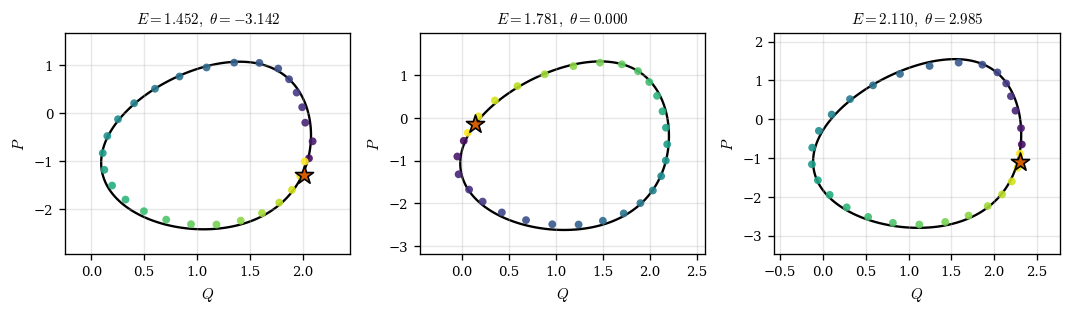

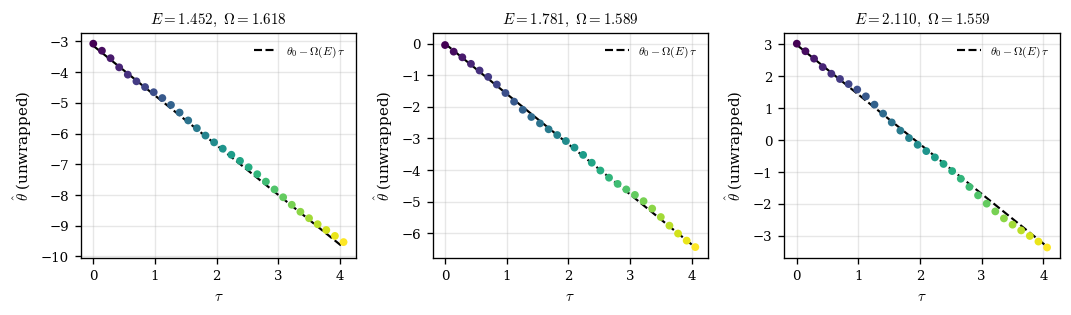

In [18]:
# recovery tables + recovered laws
report_recovery(res_train, name="HJN (pendulum)", degrees=(1, 2, 3, 4))
report_equations(res_train, name="HJN (pendulum)")



# figures
fig_E, _   = plot_pendulum_energy_time_shift(res_train, ts, closest_indices,
                                                readouts, energy_degree=3)
fig_phi, _ = plot_pendulum_phase_time_shift(res_train, ts, closest_indices)
plt.show()

-----------------------------------------------

SEED 52

-----------------------------------------------


In [5]:
save_dir_path_seed_52 = "./save_directory_ideal_pendulum_seed_52" 


with open("all_dataframes_low_samples_multiple_periods_pendulum.pkl", "rb") as f:
    df_low_samples_multiple_periods_pendulum = pickle.load(f)

test_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['data_df_low_samples_multiple_periods_pendulum']
test_id_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['id_df_low_samples_multiple_periods_pendulum']

with open("df_high_energy_low_samples_pendulum.pkl", "rb") as f:
    df_high_energy_low_samples_pendulum = pickle.load(f)

val_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_df_high_energy_low_samples_pendulum']
val_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_id_df_high_energy_low_samples_pendulum']

test_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_df_high_energy_low_samples_pendulum']
test_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_id_df_high_energy_low_samples_pendulum']


with open("all_dataframes_low_samples_pendulum.pkl", "rb") as f:
    loaded_dfs_low_samples_pendulum = pickle.load(f)

train_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_df_low_samples_pendulum']
train_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_id_df_low_samples_pendulum']




In [6]:
Tmax = 4.06
device = "cuda"
mapping_net_seed_52 = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_seed_52 = os.path.join(save_dir_path_seed_52, "best_model.pt")

load_checkpoint(path=checkpoint_path_seed_52, mapping_net=mapping_net_seed_52, device=device, optimizer=None, scheduler=None)

inverse_net_seed_52 = InverseStackedHamiltonianNetwork(forward_network=mapping_net_seed_52)

overall_seeds_save_path = "seed_results"


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [14]:
variance_results_multiple_periods_seed_52 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_seed_52,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_52 = os.path.join(overall_seeds_save_path, "variance_results_seed_52")
os.makedirs(save_dir_constancy_seed_52, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_52, "task_2_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_seed_52, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.014528
IQR: [0.011257, 0.015448]
95% BCa bootstrap CI for median (over trajectories): [0.012253, 0.015194]
N_traj=20, N_obs=144, N_permutations=20
First valid point count: 3


In [7]:
variance_results_high_energy_seed_52 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_seed_52,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_52 = os.path.join(overall_seeds_save_path, "variance_results_seed_52")
os.makedirs(save_dir_constancy_seed_52, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_52, "task_2_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_seed_52, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.029724
IQR: [0.017367, 0.045389]
95% BCa bootstrap CI for median (over trajectories): [0.017367, 0.045389]
N_traj=13, N_obs=37, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples_pendulum, train_id_df_low_samples_pendulum),
"TestA": (test_df_low_samples_multiple_periods_pendulum, test_id_df_low_samples_multiple_periods_pendulum),
"TestB": (test_df_high_energy_low_samples_pendulum, test_id_df_high_energy_low_samples_pendulum)}



res_ip_seed_52 = run_constancy_experiment_1d(
    mapping_net_seed_52, inverse_net_seed_52, Tmax=Tmax, sets=SETS, sigma2=0.1,
)



save_dir_FINAL_CONSTANCY_seed_52 = os.path.join(overall_seeds_save_path, "constancy_results_seed_52")
os.makedirs(save_dir_FINAL_CONSTANCY_seed_52, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_seed_52, "task_2_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ip_seed_52, f, protocol=pickle.HIGHEST_PROTOCOL)


model 51cd9b634a35b219 | outputs c8ebf20e1db55ab6
Train  n_traj=25  n_seg=25  D0 0.0698 [0.0537, 0.0847] | W0max 0.113 [0.0809, 0.174] | rms_delta 0.146 [0.114, 0.17] | max_delta 0.404 [0.303, 0.535] | rms_disp 2.21 [1.93, 2.44] | noise ratio 0.327 | D0/Train 1 | floor max 2.85e-06
TestA  n_traj=20  n_seg=100 D0 0.0651 [0.0575, 0.0764] | W0max 0.164 [0.132, 0.179] | rms_delta 0.145 [0.129, 0.155] | max_delta 0.558 [0.437, 0.646] | rms_disp 2.22 [2.01, 2.49] | noise ratio 0.325 | D0/Train 0.932 | floor max 5.62e-06
TestB  n_traj=13  n_seg=26  D0 0.223 [0.177, 0.388] | W0max 0.398 [0.278, 0.552] | rms_delta 0.736 [0.529, 1.25] | max_delta 1.99 [1.3, 2.54] | rms_disp 3.08 [2.92, 3.24] | noise ratio 1.65 | D0/Train 3.19 | floor max 5.12e-06


In [15]:
# Training data spans E in [1.300, 2.287]; separatrix at E=6.
TRAIN  = (1.30, 2.287)     # stay within generated training support




res_train_seed_52  = encode_grid_pendulum(mapping_net_seed_52, device, *TRAIN)

report_recovery(res_train_seed_52, name="HJN (pendulum)", degrees=(1, 2, 3, 4))
report_equations(res_train_seed_52, name="HJN (pendulum)")


readouts_seed_52 = fit_readouts(res_train_seed_52, degrees=(1, 2, 3, 4))

    
DEG_seed_52 = 3
# cached read-outs, then the time-shift test
ts_seed_52 = time_shift_test_pendulum(res_train_seed_52, mapping_net_seed_52, device, T_max=Tmax, n_tau=30,
                                energy_degree=DEG_seed_52, phase_degree=1, readouts=readouts_seed_52)


save_dir_conserved_seed_52 = os.path.join(overall_seeds_save_path, "conserved_quantities_results_seed_52")
os.makedirs(save_dir_conserved_seed_52, exist_ok=True)

readout_results_seed_52 = {
    "res_train": res_train_seed_52, "readouts": readouts_seed_52, "ts":ts_seed_52,
    "energy_degree": DEG_seed_52, "Tmax": Tmax
}



with open(os.path.join(save_dir_conserved_seed_52, "pendulum_results.pkl"), "wb") as f:
    pickle.dump(readout_results_seed_52, f)
print("saved")



[HJN (pendulum)]  ENERGY RECOVERY     train E in (1.3, 2.287)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0011 || 0.2534 [0.1292, 0.3772] p95=0.4764 (13.8%)
  2 |    0.7999 || 0.1003 [0.0497, 0.1558] p95=0.2354 (5.7%)
  3 |    0.9737 || 0.0318 [0.0143, 0.0535] p95=0.0946 (1.8%)
  4 |    0.9897 || 0.0218 [0.0111, 0.0328] p95=0.0577 (1.2%)

[HJN (pendulum)]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9985 |  0.9983 || 1.6169 [0.7454, 2.5933] p95=4.5730
  2 |  0.9996 |  0.9996 || 0.7565 [0.3244, 1.3367] p95=2.3679
  3 |  0.9998 |  0.9996 || 0.9090 [0.4681, 1.1983] p95=1.8991
  4 |  1.0000 |  1.0000 || 0.1971 [0.0983, 0.3543] p95=0.6337

------------------------------------------------------------------------------
[HJN (pendulum)]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
-----------------------------------------------------------------------------

In [16]:
save_dir_prediction_seed_52 = os.path.join(overall_seeds_save_path, "prediction_results_all_trajectories_seed_52")
os.makedirs(save_dir_prediction_seed_52, exist_ok=True)


all_trajectories_results_multiple_periods_seed_52 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_52, "task_2_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_seed_52, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_seed_52 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_52, "task_2_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_seed_52, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done


In [17]:
save_dir_prediction_single_seed_52 = os.path.join(overall_seeds_save_path, "prediction_results_single_trajectory_seed_52")
os.makedirs(save_dir_prediction_single_seed_52, exist_ok=True)


single_trajectory_multiple_periods_results_seed_52 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    5,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_52, "task_2_single_traj_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results_seed_52, f)


print("Rollout extrapolation done")

single_trajectory_high_energy_results_seed_52 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    13,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_52, "task_2_single_traj_results_high_energy.pkl"), "wb") as f:
    pickle.dump(single_trajectory_high_energy_results_seed_52, f)

print("Energy extrapolation done")


Rollout extrapolation done
Energy extrapolation done


-----------------------------------------------


SEED 62

-----------------------------------------------


In [5]:
save_dir_path_seed_62 = "./save_directory_ideal_pendulum_seed_62" 


with open("all_dataframes_low_samples_multiple_periods_pendulum.pkl", "rb") as f:
    df_low_samples_multiple_periods_pendulum = pickle.load(f)

test_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['data_df_low_samples_multiple_periods_pendulum']
test_id_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['id_df_low_samples_multiple_periods_pendulum']

with open("df_high_energy_low_samples_pendulum.pkl", "rb") as f:
    df_high_energy_low_samples_pendulum = pickle.load(f)

val_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_df_high_energy_low_samples_pendulum']
val_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_id_df_high_energy_low_samples_pendulum']

test_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_df_high_energy_low_samples_pendulum']
test_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_id_df_high_energy_low_samples_pendulum']


with open("all_dataframes_low_samples_pendulum.pkl", "rb") as f:
    loaded_dfs_low_samples_pendulum = pickle.load(f)

train_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_df_low_samples_pendulum']
train_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_id_df_low_samples_pendulum']




In [6]:
Tmax = 4.06
device = "cuda"
mapping_net_seed_62 = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_seed_62 = os.path.join(save_dir_path_seed_62, "best_model.pt")

load_checkpoint(path=checkpoint_path_seed_62, mapping_net=mapping_net_seed_62, device=device, optimizer=None, scheduler=None)

inverse_net_seed_62 = InverseStackedHamiltonianNetwork(forward_network=mapping_net_seed_62)

overall_seeds_save_path = "seed_results"


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [8]:
variance_results_multiple_periods_seed_62 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_seed_62,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_62 = os.path.join(overall_seeds_save_path, "variance_results_seed_62")
os.makedirs(save_dir_constancy_seed_62, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_62, "task_2_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_seed_62, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.126027
IQR: [0.078910, 0.256118]
95% BCa bootstrap CI for median (over trajectories): [0.085724, 0.235923]
N_traj=20, N_obs=144, N_permutations=20
First valid point count: 3


In [7]:
variance_results_high_energy_seed_62 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_seed_62,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_62 = os.path.join(overall_seeds_save_path, "variance_results_seed_62")
os.makedirs(save_dir_constancy_seed_62, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_62, "task_2_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_seed_62, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.279882
IQR: [0.142625, 0.493669]
95% BCa bootstrap CI for median (over trajectories): [0.142625, 0.493669]
N_traj=13, N_obs=37, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples_pendulum, train_id_df_low_samples_pendulum),
"TestA": (test_df_low_samples_multiple_periods_pendulum, test_id_df_low_samples_multiple_periods_pendulum),
"TestB": (test_df_high_energy_low_samples_pendulum, test_id_df_high_energy_low_samples_pendulum)}



res_ip_seed_62 = run_constancy_experiment_1d(
    mapping_net_seed_62, inverse_net_seed_62, Tmax=Tmax, sets=SETS, sigma2=0.1,
)



save_dir_FINAL_CONSTANCY_seed_62 = os.path.join(overall_seeds_save_path, "constancy_results_seed_62")
os.makedirs(save_dir_FINAL_CONSTANCY_seed_62, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_seed_62, "task_2_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ip_seed_62, f, protocol=pickle.HIGHEST_PROTOCOL)


model 64cb4d3d7c940e80 | outputs 80bbc496df85fe25
Train  n_traj=25  n_seg=25  D0 0.0411 [0.0298, 0.0633] | W0max 0.0459 [0.0347, 0.0666] | rms_delta 0.0927 [0.0666, 0.115] | max_delta 0.156 [0.12, 0.183] | rms_disp 2.21 [1.93, 2.44] | noise ratio 0.207 | D0/Train 1 | floor max 9.12e-07
TestA  n_traj=20  n_seg=100 D0 0.0508 [0.0332, 0.0579] | W0max 0.0585 [0.0446, 0.0694] | rms_delta 0.101 [0.0839, 0.114] | max_delta 0.203 [0.171, 0.219] | rms_disp 2.22 [2.01, 2.49] | noise ratio 0.226 | D0/Train 1.24 | floor max 1.45e-06
TestB  n_traj=13  n_seg=26  D0 0.213 [0.159, 0.32] | W0max 0.247 [0.199, 0.436] | rms_delta 0.704 [0.435, 0.984] | max_delta 1.16 [0.836, 1.85] | rms_disp 3.08 [2.92, 3.24] | noise ratio 1.58 | D0/Train 5.18 | floor max 1.43e-06


In [9]:
# Training data spans E in [1.300, 2.287]; separatrix at E=6.
TRAIN  = (1.30, 2.287)     # stay within generated training support




res_train_seed_62  = encode_grid_pendulum(mapping_net_seed_62, device, *TRAIN)

report_recovery(res_train_seed_62, name="HJN (pendulum)", degrees=(1, 2, 3, 4))
report_equations(res_train_seed_62, name="HJN (pendulum)")


readouts_seed_62 = fit_readouts(res_train_seed_62, degrees=(1, 2, 3, 4))

    
DEG_seed_62 = 3
# cached read-outs, then the time-shift test
ts_seed_62 = time_shift_test_pendulum(res_train_seed_62, mapping_net_seed_62, device, T_max=Tmax, n_tau=30,
                                energy_degree=DEG_seed_62, phase_degree=1, readouts=readouts_seed_62)


save_dir_conserved_seed_62 = os.path.join(overall_seeds_save_path, "conserved_quantities_results_seed_62")
os.makedirs(save_dir_conserved_seed_62, exist_ok=True)

readout_results_seed_62 = {
    "res_train": res_train_seed_62, "readouts": readouts_seed_62, "ts":ts_seed_62,
    "energy_degree": DEG_seed_62, "Tmax": Tmax
}



with open(os.path.join(save_dir_conserved_seed_62, "pendulum_results.pkl"), "wb") as f:
    pickle.dump(readout_results_seed_62, f)
print("saved")



[HJN (pendulum)]  ENERGY RECOVERY     train E in (1.3, 2.287)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0011 || 0.2526 [0.1265, 0.3795] p95=0.4792 (13.8%)
  2 |    0.8040 || 0.0974 [0.0518, 0.1526] p95=0.2457 (5.6%)
  3 |    0.9485 || 0.0468 [0.0199, 0.0755] p95=0.1293 (2.6%)
  4 |    0.9953 || 0.0153 [0.0084, 0.0222] p95=0.0370 (0.9%)

[HJN (pendulum)]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9952 |  0.9970 || 2.2530 [1.1498, 4.1905] p95=7.1577
  2 |  0.9991 |  0.9987 || 1.3683 [0.6403, 2.1758] p95=3.7726
  3 |  0.9996 |  0.9997 || 0.8106 [0.3876, 1.2795] p95=1.8505
  4 |  0.9999 |  0.9999 || 0.4204 [0.2087, 0.6595] p95=1.0295

------------------------------------------------------------------------------
[HJN (pendulum)]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
-----------------------------------------------------------------------------

In [10]:
save_dir_prediction_seed_62 = os.path.join(overall_seeds_save_path, "prediction_results_all_trajectories_seed_62")
os.makedirs(save_dir_prediction_seed_62, exist_ok=True)


all_trajectories_results_multiple_periods_seed_62 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_62, "task_2_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_seed_62, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_seed_62 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_62, "task_2_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_seed_62, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done


In [11]:
save_dir_prediction_single_seed_62 = os.path.join(overall_seeds_save_path, "prediction_results_single_trajectory_seed_62")
os.makedirs(save_dir_prediction_single_seed_62, exist_ok=True)


single_trajectory_multiple_periods_results_seed_62 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    5,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_62, "task_2_single_traj_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results_seed_62, f)


print("Rollout extrapolation done")

single_trajectory_high_energy_results_seed_62 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    13,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    case="ideal_pendulum",
    length=1.0, k=1, mass=1, g=3.0, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_62, "task_2_single_traj_results_high_energy.pkl"), "wb") as f:
    pickle.dump(single_trajectory_high_energy_results_seed_62, f)

print("Energy extrapolation done")


Rollout extrapolation done
Energy extrapolation done


--------------------------------------

NO HSIC ABLIATION

---------------------------------------------------------------------

In [5]:
save_dir_path_no_HSIC = "./save_directory_ideal_pendulum_NO_HSIC_1" 


with open("all_dataframes_low_samples_multiple_periods_pendulum.pkl", "rb") as f:
    df_low_samples_multiple_periods_pendulum = pickle.load(f)

test_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['data_df_low_samples_multiple_periods_pendulum']
test_id_df_low_samples_multiple_periods_pendulum = df_low_samples_multiple_periods_pendulum['id_df_low_samples_multiple_periods_pendulum']

with open("df_high_energy_low_samples_pendulum.pkl", "rb") as f:
    df_high_energy_low_samples_pendulum = pickle.load(f)

val_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_df_high_energy_low_samples_pendulum']
val_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['val_id_df_high_energy_low_samples_pendulum']

test_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_df_high_energy_low_samples_pendulum']
test_id_df_high_energy_low_samples_pendulum = df_high_energy_low_samples_pendulum['test_id_df_high_energy_low_samples_pendulum']


with open("all_dataframes_low_samples_pendulum.pkl", "rb") as f:
    loaded_dfs_low_samples_pendulum = pickle.load(f)

train_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_df_low_samples_pendulum']
train_id_df_low_samples_pendulum = loaded_dfs_low_samples_pendulum['train_id_df_low_samples_pendulum']




In [6]:
Tmax = 4.06
device = "cuda"
mapping_net_no_HSIC = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_no_HSIC = os.path.join(save_dir_path_no_HSIC, "best_model.pt")

load_checkpoint(path=checkpoint_path_no_HSIC, mapping_net=mapping_net_no_HSIC, device=device, optimizer=None, scheduler=None)

inverse_net_no_HSIC = InverseStackedHamiltonianNetwork(forward_network=mapping_net_no_HSIC)

overall_ablation_save_path = "no_HSIC_ablation_results"


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [7]:
variance_results_multiple_periods_no_HSIC = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_no_HSIC,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=False,)

save_dir_constancy_no_HSIC = os.path.join(overall_ablation_save_path, "variance_results_no_HSIC")
os.makedirs(save_dir_constancy_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_constancy_no_HSIC, "task_2_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_no_HSIC, f)



In [7]:
variance_results_high_energy_no_HSIC = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_no_HSIC,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_no_HSIC = os.path.join(overall_ablation_save_path, "variance_results_no_HSIC")
os.makedirs(save_dir_constancy_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_constancy_no_HSIC, "task_2_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_no_HSIC, f)



Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.151902
IQR: [0.088265, 0.631929]
95% BCa bootstrap CI for median (over trajectories): [0.088265, 0.631929]
N_traj=13, N_obs=37, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples_pendulum, train_id_df_low_samples_pendulum),
"TestA": (test_df_low_samples_multiple_periods_pendulum, test_id_df_low_samples_multiple_periods_pendulum),
"TestB": (test_df_high_energy_low_samples_pendulum, test_id_df_high_energy_low_samples_pendulum)}



res_ip_no_HSIC = run_constancy_experiment_1d(
    mapping_net_no_HSIC, inverse_net_no_HSIC, Tmax=Tmax, sets=SETS, sigma2=0.1,
)



save_dir_FINAL_CONSTANCY_no_HSIC = os.path.join(overall_ablation_save_path, "constancy_results_no_HSIC")
os.makedirs(save_dir_FINAL_CONSTANCY_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_no_HSIC, "task_2_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ip_no_HSIC, f, protocol=pickle.HIGHEST_PROTOCOL)


model 1810eceb88246607 | outputs 221d45e771de482a
Train  n_traj=25  n_seg=25  D0 0.0403 [0.034, 0.0539] | W0max 0.0446 [0.0379, 0.0668] | rms_delta 0.0893 [0.0693, 0.106] | max_delta 0.151 [0.122, 0.179] | rms_disp 2.21 [1.93, 2.44] | noise ratio 0.2 | D0/Train 1 | floor max 9.61e-07
TestA  n_traj=20  n_seg=100 D0 0.0413 [0.034, 0.0526] | W0max 0.0506 [0.0441, 0.0599] | rms_delta 0.0888 [0.0812, 0.103] | max_delta 0.172 [0.157, 0.2] | rms_disp 2.22 [2.01, 2.49] | noise ratio 0.199 | D0/Train 1.02 | floor max 1.58e-06
TestB  n_traj=13  n_seg=26  D0 0.218 [0.177, 0.344] | W0max 0.262 [0.211, 0.439] | rms_delta 0.694 [0.445, 1.06] | max_delta 1.17 [0.888, 1.88] | rms_disp 3.08 [2.92, 3.24] | noise ratio 1.55 | D0/Train 5.4 | floor max 1.31e-06


In [5]:
"""
FULL, SELF-CONTAINED latent <-> physics recovery for HJN -- IDEAL PENDULUM
(oscillatory regime).

    H = 1/2 p^2 + omega0_sq * (1 - cos q),   omega0_sq = g/l = 3,   separatrix E = 6.

This file bundles the feature-agnostic recovery / reporting machinery (the SHO
module's helpers, reproduced verbatim) together with the pendulum-specific physics,
so the ONLY thing you must supply is a trained encoder `mapping_net` and its
`device`.  Run by pasting into a notebook cell, or:  %run -i pendulum_recovery_full.py

PHYSICS CHOICE -- the action-angle theta (not the raw elliptic phase delta).
The SHO's second invariant phi is the polar angle of a circular orbit.  The faithful
pendulum analogue is the ACTION-ANGLE variable theta in [-pi, pi): uniform in time,
2*pi-periodic (so cos/sin/atan2 + unwrap port verbatim) and giving a rectangular
(E, theta) grid.  Its time rate is the anharmonic frequency
    Omega(E) = 2*pi / T(E) = pi * omega0 / (2 K(m)),     m = E / (2 omega0^2),
which DECREASES with energy -- the pendulum slowdown the SHO cannot show.  That
energy-dependent slope in the time-shift test is the physics payoff.  (The raw
elliptic phase delta would instead give a constant slope -omega0 for every state, but
hides the anharmonicity inside K(m) and forces a non-rectangular grid: the weaker
choice here.)  Throughout, res['phi'] HOLDS theta, so every generic reporter that
reads res['phi'] as "the angle" works unchanged.
"""

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import ellipk, ellipj
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

OMEGA0_SQ = 3.0                 # g/l for this task (g=3, l=1)  => omega0 = sqrt(3)
E_SEP     = 2.0 * OMEGA0_SQ     # separatrix energy = 6


# ======================================================================
# Encoder interface  (the one piece that talks to the trained model)
# ======================================================================
def encode_at_reference_time(mapping_net, q, p, device, reference_time=0.0):
    """No torch.no_grad(): the HJL forward uses autograd internally; .detach() outputs."""
    import torch
    q_t = torch.as_tensor(np.asarray(q, np.float32), device=device)
    p_t = torch.as_tensor(np.asarray(p, np.float32), device=device)
    t_t = torch.full_like(q_t, float(reference_time))
    Q, P, _ = mapping_net(q_t, p_t, t_t)
    return Q.detach().cpu().numpy().astype(float), P.detach().cpu().numpy().astype(float)


# ======================================================================
# Generic polynomial read-out machinery  (feature-agnostic; verbatim from SHO module)
# ======================================================================
def _r2(y, yhat):
    y = np.asarray(y, float)
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


def _poly(degree, scale=False):
    """Polynomial least-squares read-out. `scale` standardises inputs; it leaves
    predictions and R^2 unchanged (invertible affine reparam of the features) and only
    changes coefficient values, so it is OFF by default so the fitted model IS the
    equation reported in raw (Q,P) units. Turn ON only if a high-degree solve is
    ill-conditioned; it never affects results."""
    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree, include_bias=True),
              LinearRegression(fit_intercept=False)]
    return make_pipeline(*steps)


def _oof_scalar(feats, y, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, float); pred = np.zeros_like(y)
    for tr, te in kf.split(feats):
        pred[te] = _poly(degree, scale).fit(feats[tr], y[tr]).predict(feats[te])
    return pred




def _oof_phase(feats, phi, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    c, s = np.cos(phi), np.sin(phi); ch, sh = np.zeros_like(c), np.zeros_like(s)
    for tr, te in kf.split(feats):
        m = _poly(degree, scale).fit(feats[tr], np.column_stack([c[tr], s[tr]]))
        o = m.predict(feats[te]); ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)



def angular_error_deg(phi_true, phi_hat):
    d = np.arctan2(np.sin(phi_hat - phi_true), np.cos(phi_hat - phi_true))
    return np.abs(d) * 180.0 / np.pi


def err_stats(abs_err):
    """Descriptive spread (no distributional assumption, no bootstrap)."""
    a = np.asarray(abs_err, float)
    q25, med, q75, p95 = np.percentile(a, [25, 50, 75, 95])
    return dict(median=med, p25=q25, p75=q75, p95=p95, mean=a.mean())


def _terms(names, coef):
    """Format a polynomial as a coefficient string in raw (Q,P) units."""
    parts = [f"{c:+.4f}" if n == "1" else f"{c:+.4f}·{n}" for n, c in zip(names, coef)]
    return " ".join(parts).replace("Q P", "QP")


def energy_equation(feats, E, degree, scale=False):
    """Fit the energy read-out; expose coefficients (raw Q,P units) AND the fitted
    model (reused as the time-shift instrument). Degree 2 also returns the quadratic
    part's eigenvalues (positive-definite => closed level sets)."""
    model = _poly(degree, scale).fit(feats, E)
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    coef = model.named_steps["linearregression"].coef_
    out = dict(names=names, coef=coef, degree=degree, model=model)
    if degree == 2 and feats.shape[1] == 2 and not scale:
        d = dict(zip(names, coef))
        M = np.array([[d["Q^2"], d["Q P"] / 2], [d["Q P"] / 2, d["P^2"]]])
        eig = np.linalg.eigvalsh(M)
        out.update(eig=eig, posdef=bool(eig.min() > 0))
    return out


def phase_poly_angle(feats, phi, degree, scale=False):
    """Fit the phase read-out; expose the displayed equation (atan2 of sin-/cos-polys,
    raw Q,P units) AND the fitted multi-output model (reused as the time-shift
    instrument)."""
    model = _poly(degree, scale).fit(feats, np.column_stack([np.cos(phi), np.sin(phi)]))
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    cos_coef, sin_coef = model.named_steps["linearregression"].coef_  # rows: cos, sin
    o = model.predict(feats)
    phi_hat = np.arctan2(o[:, 1], o[:, 0])
    return dict(num=_terms(names, sin_coef), den=_terms(names, cos_coef),
                err=angular_error_deg(phi, phi_hat), model=model)


def _fmt(s):
    return f"{s['median']:.4f} [{s['p25']:.4f}, {s['p75']:.4f}] p95={s['p95']:.4f}"


def report_recovery(res_train, name="HJN", degrees=(1, 2, 3, 4), scale=False):
    """R^2 ladders + descriptive error fields, in-distribution (train CV only).
    Feature-agnostic."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "=" * 78
    print(f"\n{bar}\n[{name}]  ENERGY RECOVERY     "
          f"train E in {res_train['band']}\n{bar}")
    print(f"{'deg':>3} | {'train R2':>9} || train |dE| med[IQR] p95 (rel%)")
    for dg in degrees:
        oof = _oof_scalar(ft, Et, dg, scale=scale)
        rt = np.median(np.abs(Et - oof) / np.abs(Et)) * 100
        print(f"{dg:>3} | {_r2(Et, oof):>9.4f} || "
              f"{_fmt(err_stats(np.abs(Et - oof)))} ({rt:.1f}%)")

    print(f"\n{bar}\n[{name}]  PHASE RECOVERY  (angular error in degrees)\n{bar}")
    print(f"{'deg':>3} | {'cos R2':>7} | {'sin R2':>7} || train ang.err med[IQR] p95")
    for dg in degrees:
        ph_tr = _oof_phase(ft, pt, dg, scale=scale)
        print(f"{dg:>3} | {_r2(np.cos(pt), np.cos(ph_tr)):>7.4f} | "
              f"{_r2(np.sin(pt), np.sin(ph_tr)):>7.4f} || "
              f"{_fmt(err_stats(angular_error_deg(pt, ph_tr)))}")


def report_equations(res_train, name="HJN"):
    """Recovered structural laws (assumes 2 canonical latents). NOTE for the pendulum:
    res['phi'] is the action-angle theta, and the degree-2 posdef check certifies only
    the LEADING-ORDER closed level sets -- the faithful energy law is whatever minimal
    degree report_recovery shows."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "-" * 78
    print(f"\n{bar}\n[{name}]  RECOVERED LAWS  (raw Q,P units; coefficients are "
          f"gauge-dependent -- the STRUCTURE is the robust claim)\n{bar}")

    eq2 = energy_equation(ft, Et, 2)
    print("ENERGY (degree-2):")
    print("  E = " + _terms(eq2["names"], np.round(eq2["coef"], 4)))
    print(f"  eigenvalues of quadratic part = {eq2['eig'].round(3)}  "
          f"positive-definite = {'YES' if eq2['posdef'] else 'NO'}  (=> closed level sets)")
    eq3 = energy_equation(ft, Et, 3)
    print("ENERGY (degree-3):")
    print("  E = " + _terms(eq3["names"], np.round(eq3["coef"], 4)))

    p1 = phase_poly_angle(ft, pt, 1); s1 = err_stats(p1["err"])
    print("PHASE (degree-1 affine-angle):")
    print(f"  angle_hat = atan2( {p1['num']} ,  {p1['den']} )")
    print(f"  angular error: median {s1['median']:.3f} deg "
          f"[{s1['p25']:.3f}, {s1['p75']:.3f}]  p95={s1['p95']:.3f} deg")
    p2 = phase_poly_angle(ft, pt, 2); s2 = err_stats(p2["err"])
    print("PHASE (degree-2):")
    print("  angle_hat = atan2( NUM , DEN ) with")
    print(f"    NUM = {p2['num']}")
    print(f"    DEN = {p2['den']}")
    print(f"  angular error: median {s2['median']:.3f} deg "
          f"[{s2['p25']:.3f}, {s2['p75']:.3f}]  p95={s2['p95']:.3f} deg")


def fit_readouts(res_train, degrees=(1, 2, 3, 4), scale=False):
    """Fit, once, the energy and phase read-outs for every requested degree on the t=0
    grid, caching the fitted models. These ARE the models report_equations displays, so
    the time-shift test applies the displayed equations. Phase models are multi-output
    ([cos, sin])."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    energy = {d: energy_equation(ft, Et, d, scale)["model"] for d in degrees}
    phase  = {d: phase_poly_angle(ft, pt, d, scale)["model"] for d in degrees}
    return dict(energy=energy, phase=phase, degrees=tuple(degrees))


def predict_energy(readouts, feats, degree):
    return readouts["energy"][degree].predict(feats)


def predict_phase(readouts, feats, degree):
    o = readouts["phase"][degree].predict(feats)
    return np.arctan2(o[:, 1], o[:, 0])


# ======================================================================
# Pendulum physics  (scipy's ellipk / ellipj take the PARAMETER m = k^2)
# ======================================================================
def modulus_sq(E, omega0_sq=OMEGA0_SQ):
    """Elliptic parameter m = k^2 = sin^2(theta_max/2) = E / (2 omega0^2)."""
    return np.asarray(E, float) / (2.0 * omega0_sq)


def pendulum_period(E, omega0_sq=OMEGA0_SQ):
    """Exact libration period  T(E) = 4 K(m) / omega0."""
    return 4.0 * ellipk(modulus_sq(E, omega0_sq)) / np.sqrt(omega0_sq)


def pendulum_frequency(E, omega0_sq=OMEGA0_SQ):
    """Anharmonic angular frequency  Omega(E) = 2 pi / T(E) = pi omega0 / (2 K(m))."""
    return 2.0 * np.pi / pendulum_period(E, omega0_sq)


def pendulum_initial_conditions(E, theta, omega0_sq=OMEGA0_SQ):
    """(E, theta) -> (q, p) on the t=0 section, oscillatory regime.  theta is the
    action-angle (uniform-in-time) phase in [-pi, pi), mapped to the Jacobi argument by
    xi = (2 K(m)/pi) theta so one turn of theta is one period 4K of sn:
        sin(q/2) = k sn(xi, m),    p = sqrt(2E) cn(xi, m).
    Exact: H = E(cn^2+sn^2) = E.  theta=0 -> (0, sqrt(2E)); theta=pi/2 -> (theta_max, 0);
    E -> 0 recovers the SHO map (sn->sin, cn->cos)."""
    E     = np.asarray(E, float)
    theta = np.asarray(theta, float)
    m  = modulus_sq(E, omega0_sq)
    k  = np.sqrt(m)
    K  = ellipk(m)
    xi = (2.0 * K / np.pi) * theta
    sn, cn, dn, _ = ellipj(xi, m)
    q = 2.0 * np.arcsin(np.clip(k * sn, -1.0, 1.0))
    p = np.sqrt(2.0 * E) * cn
    return q, p


def build_grid_pendulum(E_lo, E_hi, n_E=40, n_theta=40, omega0_sq=OMEGA0_SQ):
    Ea = np.linspace(E_lo, E_hi, n_E)
    ta = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
    EE, TT = np.meshgrid(Ea, ta, indexing="ij")
    E, theta = EE.ravel(), TT.ravel()
    q, p = pendulum_initial_conditions(E, theta, omega0_sq)
    return E, theta, q, p


def encode_grid_pendulum(mapping_net, device, E_lo, E_hi,
                         n_E=40, n_theta=40, reference_time=0.0, omega0_sq=OMEGA0_SQ):
    """'phi' key holds the action-angle theta, so every loaded reporter works unchanged."""
    E, theta, q, p = build_grid_pendulum(E_lo, E_hi, n_E, n_theta, omega0_sq)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    return dict(E=E, phi=theta, q=q, p=p,
                feats=np.column_stack([Q, P]), band=(E_lo, E_hi))


# ======================================================================
# Time-shift test  --  phase slope is now -Omega(E), energy-dependent
# ======================================================================
def time_shift_test_pendulum(res_train, mapping_net, device, T_max, n_tau=25,
                             energy_degree=3, phase_degree=2,
                             omega0_sq=OMEGA0_SQ, n_E_bins=5, readouts=None):
    """Re-encode each fixed state (q0,p0) at tau in [0, T_max], varying ONLY time.
    Energy: flat in tau (slope ~ 0).  Phase: linear with per-state slope -Omega(E_state).
    The SHO had one slope -omega for all states; here it is a CURVE in E (the anharmonic
    frequency), so we report (a) the residual of each fitted slope against its OWN
    -Omega(E), and (b) fitted vs theoretical slope per energy bin (the slowdown).
    Read-outs are cached t=0 fits used as instruments; the sweep stays in-band (only
    theta shifts), so use the highest degree whose IN-BAND fit has plateaued
    (energy ~3-4, phase ~2-3)."""
    q0, p0 = res_train["q"], res_train["p"]
    E_true = res_train["E"]
    theta0 = res_train["phi"]
    Omega  = pendulum_frequency(E_true, omega0_sq)
    if readouts is None:
        readouts = fit_readouts(res_train, degrees=(energy_degree, phase_degree))

    taus   = np.linspace(0.0, T_max, n_tau)
    E_hat  = np.empty((n_tau, q0.size)); th_hat = np.empty((n_tau, q0.size))
    Q_full = np.empty((n_tau, q0.size)); P_full = np.empty((n_tau, q0.size))
    for i, tau in enumerate(taus):
        Q, P = encode_at_reference_time(mapping_net, q0, p0, device, tau)
        F = np.column_stack([Q, P])
        E_hat[i]  = predict_energy(readouts, F, energy_degree)
        th_hat[i] = predict_phase(readouts, F, phase_degree)
        Q_full[i], P_full[i] = Q, P

    A = np.vstack([taus, np.ones_like(taus)]).T

    cE, *_      = np.linalg.lstsq(A, E_hat, rcond=None)
    e_slope     = cE[0]
    per_tau_med = np.median(np.abs(E_hat - E_true[None, :]), axis=1)

    th_un       = np.unwrap(th_hat, axis=0)
    cP, *_      = np.linalg.lstsq(A, th_un, rcond=None)
    p_slope, p_int = cP[0], cP[1]
    resid_deg   = np.abs(th_un - A @ cP).ravel() * 180.0 / np.pi
    ic_err_deg  = np.abs(np.arctan2(np.sin(p_int - theta0),
                                    np.cos(p_int - theta0))) * 180.0 / np.pi
    slope_resid = np.abs(p_slope - (-Omega))

    bar = "=" * 78
    print(f"\n{bar}\nTIME-SHIFT TEST  (pendulum)  fixed state re-encoded at "
          f"tau in [0, {T_max:.3f}],  {q0.size} pts x {n_tau} times\n"
          f"read-outs fit on t=0 grid: energy degree {energy_degree}, "
          f"phase degree {phase_degree}\n{bar}")
    print("ENERGY  (predicted time-invariant: dE/dtau ~ 0)")
    print(f"  dE/dtau                     : {_fmt(err_stats(e_slope))}   (energy/time)")
    print(f"  median_j |E_hat-E|, over tau : {_fmt(err_stats(per_tau_med))}")
    print("PHASE   (predicted slope = -Omega(E), ENERGY-DEPENDENT)")
    print(f"  Omega(E) theory range       : [{Omega.min():.3f}, {Omega.max():.3f}]"
          f"   (omega0 = {np.sqrt(omega0_sq):.3f})")
    print(f"  fitted dtheta/dtau (5-95%)  : [{np.percentile(p_slope,5):.3f}, "
          f"{np.percentile(p_slope,95):.3f}]")
    print(f"  |dtheta/dtau - (-Omega(E))| : {_fmt(err_stats(slope_resid))}   (rad/time)")
    print(f"  linear-fit residual         : {_fmt(err_stats(resid_deg))}  deg")
    print(f"  intercept err vs theta0     : {_fmt(err_stats(ic_err_deg))}  deg")

    edges = np.linspace(E_true.min(), E_true.max(), n_E_bins + 1)
    idx_b = np.clip(np.digitize(E_true, edges) - 1, 0, n_E_bins - 1)
    print(f"\n  per-energy-bin slope (the anharmonic frequency curve):")
    print(f"  {'E bin':>16} | {'-Omega(E)':>10} | {'fitted med':>11} | {'|diff|':>7}")
    binned = []
    for b in range(n_E_bins):
        mask = idx_b == b
        if not mask.any():
            continue
        Ec       = 0.5 * (edges[b] + edges[b + 1])
        th_slope = -pendulum_frequency(Ec, omega0_sq)
        fit_med  = np.median(p_slope[mask])
        binned.append((Ec, th_slope, fit_med))
        print(f"  [{edges[b]:6.3f},{edges[b+1]:6.3f}] | {th_slope:>10.3f} | "
              f"{fit_med:>11.3f} | {abs(fit_med - th_slope):>7.3f}")

    return dict(E_hat=E_hat, phi_hat=th_hat, Q_full=Q_full, P_full=P_full,
                taus=taus, Omega=Omega, p_slope=p_slope,
                binned=np.array(binned), readouts=readouts)


# ======================================================================
# Paper styling + figures
# ======================================================================
def apply_style():
    mpl.rcParams.update({
        'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.dpi': 300, 'figure.dpi': 120,
        'savefig.bbox': 'tight', 'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9,
        'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
        'axes.grid': True, 'grid.alpha': 0.3, 'axes.linewidth': 0.8, 'lines.linewidth': 1.2,
        'font.family': 'serif', 'text.usetex': False, 'mathtext.fontset': 'cm',
    })


def plot_pendulum_energy_time_shift(res_train, ts, closest_indices, readouts,
                                    energy_degree=3, pad=0.18, grid_n=300, save=True,
                                    fname="energy_recovery_time_shift_pendulum.pdf"):
    """Recovered level set E_hat=f(Q,P)=const + time-shifted encodings. Degree-agnostic:
    evaluates the ACTUAL cached read-out on a Q-P mesh and draws the single contour (no
    closed-form quadratic root, so any energy degree works and no COEFFS transcription)."""
    Q_full, P_full, taus = ts["Q_full"], ts["P_full"], ts["taus"]
    model = readouts["energy"][energy_degree]
    n = len(closest_indices)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 2.7), squeeze=False)
    axes = axes[0]
    for ax, idx in zip(axes, closest_indices):
        Ec, th_c = float(res_train["E"][idx]), float(res_train["phi"][idx])
        xp, up   = Q_full[:, idx], P_full[:, idx]
        qmin, qmax = xp.min(), xp.max(); pmin, pmax = up.min(), up.max()
        dq = (qmax - qmin) or 1.0; dp = (pmax - pmin) or 1.0
        qs = np.linspace(qmin - pad * dq, qmax + pad * dq, grid_n)
        ps = np.linspace(pmin - pad * dp, pmax + pad * dp, grid_n)
        QQ, PP = np.meshgrid(qs, ps)
        EE = model.predict(np.column_stack([QQ.ravel(), PP.ravel()])).reshape(QQ.shape)
        ax.contour(QQ, PP, EE, levels=[Ec], colors="k", linewidths=1.4, zorder=1)
        ax.scatter(xp, up, c=taus, cmap="viridis", s=22, alpha=0.9,
                   edgecolors="none", zorder=3)
        ax.scatter(xp[0], up[0], marker="*", s=130, color="#D55E00",
                   edgecolors="black", linewidths=1.0, zorder=5)
        ax.set_title(rf"$E={Ec:.3f},\ \theta={th_c:.3f}$", fontweight="bold")
        ax.set_xlabel(r"$Q$"); ax.set_ylabel(r"$P$")
    fig.tight_layout()
    if save:
        d = Path("./manuscript_figures"); d.mkdir(exist_ok=True)
        fig.savefig(d / fname); fig.savefig((d / fname).with_suffix(".png"))
        print("saved:", d / fname)
    return fig, axes


def plot_pendulum_phase_time_shift(res_train, ts, closest_indices,
                                   omega0_sq=OMEGA0_SQ, save=True,
                                   fname="phase_recovery_time_shift_pendulum.pdf"):
    """Recovered theta_hat(tau) vs the anharmonic line theta0 - Omega(E) tau. The dashed
    line's SLOPE differs per panel (per energy) -- the visual signature of anharmonicity
    that the SHO (single slope) cannot produce."""
    phi_hat, taus = ts["phi_hat"], ts["taus"]
    n = len(closest_indices)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 2.7), squeeze=False)
    axes = axes[0]
    for ax, idx in zip(axes, closest_indices):
        Ec, th0 = float(res_train["E"][idx]), float(res_train["phi"][idx])
        Omega   = pendulum_frequency(Ec, omega0_sq)
        th_un   = np.unwrap(phi_hat[:, idx])
        ax.scatter(taus, th_un, c=taus, cmap="viridis", s=22, zorder=3, edgecolors="none")
        ax.plot(taus, th0 - Omega * taus, "k--", lw=1.3, zorder=2,
                label=r"$\theta_0-\Omega(E)\,\tau$")
        ax.set_title(rf"$E={Ec:.3f},\ \Omega={Omega:.3f}$", fontweight="bold")
        ax.set_xlabel(r"$\tau$"); ax.set_ylabel(r"$\hat\theta$ (unwrapped)")
        ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    if save:
        d = Path("./manuscript_figures"); d.mkdir(exist_ok=True)
        fig.savefig(d / fname); fig.savefig((d / fname).with_suffix(".png"))
        print("saved:", d / fname)
    return fig, axes


# ======================================================================
# Optional qualitative sweeps (pendulum versions)
# ======================================================================
def plot_energy_sweep_pendulum(mapping_net, device, E_lo, E_hi, label,
                               theta_fixed=np.pi / 4, n=400, reference_time=0.0):
    E = np.linspace(E_lo, E_hi, n)
    q, p = pendulum_initial_conditions(E, np.full_like(E, theta_fixed))
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    a1.plot(E, Q, "b"); a1.set_ylabel("Q"); a1.grid(True); a1.set_title(f"Q vs E [{label}]")
    a2.plot(E, P, "r"); a2.set_ylabel("P"); a2.set_xlabel("E"); a2.grid(True); a2.set_title("P vs E")
    plt.tight_layout(); plt.show()


def plot_phase_sweep_pendulum(mapping_net, device, E_fixed=1.8, n=400, reference_time=0.0):
    theta = np.linspace(-np.pi, np.pi, n)
    q, p = pendulum_initial_conditions(np.full_like(theta, E_fixed), theta)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4))
    a1.plot(theta, Q, "b"); a1.set_xlabel("theta"); a1.set_ylabel("Q"); a1.grid(True)
    a2.plot(theta, P, "r"); a2.set_xlabel("theta"); a2.set_ylabel("P"); a2.grid(True)
    a3.plot(Q, P, "purple"); a3.set_xlabel("Q"); a3.set_ylabel("P"); a3.grid(True)
    a3.set_aspect("equal", adjustable="datalim"); a3.set_title("(Q,P) loop")
    plt.tight_layout(); plt.show()











In [9]:
# Training data spans E in [1.300, 2.287]; separatrix at E=6.
TRAIN  = (1.30, 2.287)     # stay within generated training support




res_train_no_HSIC  = encode_grid_pendulum(mapping_net_no_HSIC, device, *TRAIN)

report_recovery(res_train_no_HSIC, name="HJN (pendulum)", degrees=(1, 2, 3, 4))
report_equations(res_train_no_HSIC, name="HJN (pendulum)")


readouts_no_HSIC = fit_readouts(res_train_no_HSIC, degrees=(1, 2, 3, 4))

    
DEG_no_HSIC = 3
# cached read-outs, then the time-shift test
ts_no_HSIC = time_shift_test_pendulum(res_train_no_HSIC, mapping_net_no_HSIC, device, T_max=Tmax, n_tau=30,
                                energy_degree=DEG_no_HSIC, phase_degree=1, readouts=readouts_no_HSIC)


save_dir_conserved_no_HSIC = os.path.join(overall_ablation_save_path, "conserved_quantities_results_no_HSIC")
os.makedirs(save_dir_conserved_no_HSIC, exist_ok=True)

readout_results_no_HSIC = {
    "res_train": res_train_no_HSIC, "readouts": readouts_no_HSIC, "ts":ts_no_HSIC,
    "energy_degree": DEG_no_HSIC, "Tmax": Tmax
}



with open(os.path.join(save_dir_conserved_no_HSIC, "pendulum_results.pkl"), "wb") as f:
    pickle.dump(readout_results_no_HSIC, f)
print("saved")



[HJN (pendulum)]  ENERGY RECOVERY     train E in (1.3, 2.287)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0012 || 0.2524 [0.1266, 0.3788] p95=0.4807 (13.8%)
  2 |    0.7848 || 0.0953 [0.0432, 0.1633] p95=0.2560 (5.5%)
  3 |    0.9123 || 0.0638 [0.0312, 0.1030] p95=0.1621 (3.6%)
  4 |    0.9990 || 0.0057 [0.0025, 0.0094] p95=0.0191 (0.3%)

[HJN (pendulum)]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9967 |  0.9970 || 2.4055 [1.1058, 3.8104] p95=6.1456
  2 |  0.9993 |  0.9984 || 1.3444 [0.6049, 2.0873] p95=3.9044
  3 |  0.9995 |  0.9996 || 0.9059 [0.3590, 1.5545] p95=2.3023
  4 |  0.9998 |  0.9998 || 0.6470 [0.3440, 0.9192] p95=1.3360

------------------------------------------------------------------------------
[HJN (pendulum)]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
-----------------------------------------------------------------------------

In [10]:
save_dir_prediction_no_HSIC = os.path.join(overall_ablation_save_path, "prediction_results_all_trajectories_no_HSIC")
os.makedirs(save_dir_prediction_no_HSIC, exist_ok=True)


all_trajectories_results_multiple_periods_no_HSIC = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods_pendulum,
    test_df_low_samples_multiple_periods_pendulum,
    mapping_net_no_HSIC,
    inverse_net_no_HSIC,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_no_HSIC, "task_2_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_no_HSIC, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_no_HSIC = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples_pendulum,
    test_df_high_energy_low_samples_pendulum,
    mapping_net_no_HSIC,
    inverse_net_no_HSIC,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_no_HSIC, "task_2_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_no_HSIC, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done
